# Grover's Quantum Search Algorithm — from Predicate to Amplitude Amplification

A complete from-scratch build of Grover search in NumPy: an **unstructured database** that is a
real predicate (subset-sum and 3-SAT, solved by classical brute force first), the oracle *derived
from* that predicate in both the phase-flip and bit-flip forms, a diffusion operator built twice —
as an explicit matrix and as a Hadamard / multi-controlled-Z circuit — the closed form for the
amplification, the query-complexity and optimality story, finite-shot sampling, and a depolarising
noise budget that says how much of the speedup survives on imperfect hardware.

| Part | Topic | What you get |
|---|---|---|
| 0 | Simulator | state vectors, gate matrices, exact multi-controlled gates (and the parity trap that naive chains walk into) |
| 1 | The database | subset-sum and 3-SAT predicates, marked items found by brute force |
| 2 | Oracles | phase-flip and bit-flip forms, proved to give identical amplification |
| 3 | Diffusion | `2\|s⟩⟨s\| - I` as a matrix and as `H^n (2\|0⟩⟨0\| - I\|) H^n`, same matrix |
| 4 | Closed form | `sin((2t+1)θ)`, `t*`, the `M = N/2` dead end, the exact-success family |
| 5 | Worked example | 3-qubit search, every amplitude printed step by step, finite shots |
| 6 | Query complexity | `√N` speedup table, log-log slope, BBBV optimality |
| 7 | Noise | per-gate depolarising on the diffusion operator, where the advantage dies |
| 8 | Self-tests | 60+ assertions |
| 9 | Qiskit | optional install, `GroverOperator`, statevectors compared by ray overlap |

**Run it in Google Colab:** `File > Open notebook > Upload`, then `Runtime > Run all`.
Parts 0–8 need only NumPy and Matplotlib. Part 9 installs Qiskit itself and is optional.

**The algorithm in one paragraph.** Write the search space as `N = 2^n` bit strings and let
`f(x) ∈ {0, 1}` be the predicate. Start in the uniform superposition `|s⟩ = H^{⊗n}|0⟩`, the state
that contains every candidate at once with amplitude `1/√N`. One Grover iteration is

$$Q = \big(2|s\rangle\langle s| - I\big)\;O_f , \qquad O_f|x\rangle = (-1)^{f(x)}|x\rangle$$

an oracle phase-flip followed by a reflection about `|s⟩`. Those two reflections are a rotation by
`2θ` inside the two-dimensional plane spanned by the marked and unmarked uniform states, with

$$\sin\theta = \sqrt{M/N}, \qquad |s\rangle = \sqrt{M/N}\,|\text{marked}\rangle + \sqrt{1 - M/N}\,|\text{unmarked}\rangle$$

so after `t` iterations the marked amplitude is exactly `sin((2t+1)θ)` and the success probability is

$$P(t) = \sin^2\!\big((2t+1)\theta\big), \qquad t^{*} = \Big\lfloor \frac{\pi}{4}\sqrt{N/M} \Big\rfloor \approx \frac{\pi}{4}\frac{1}{\sin\theta}$$

Rotate to `P ≈ 1` and stop. `P(t)` is not monotone: run past `t*` and the amplitude
leaves the target again, so "more iterations" is never free (Part 4 shows the whole
curve, including the point where it falls back to the classical value).

**Conventions, stated once.** Qubit 0 is the **leftmost / most significant** bit of a ket:
`|b_0 b_1 ... b_{n-1}⟩` has index `Σ_q b_q 2^{n-1-q}`. Gates are applied by tensor contraction with
`targets[0]` = the most significant index of the gate's own matrix. Register basis is the
computational `Z` basis, amplitudes are complex, probabilities are `|amplitude|²` and always sum to
1 by construction. The single-qubit gates are `H = (X+Z)/√2`, `X`, `Y`, `Z` and `CNOT` is
control-first, i.e. `CX = |0⟩⟨0| ⊗ I + |1⟩⟨1| ⊗ X`. Qiskit, used only in Part 9, orders qubits the
other way round and needs an explicit index flip.



## Part 0 · The simulator

Everything below is a state vector of `2ⁿ` complex amplitudes plus a gate that reshapes it into a
rank-`n` tensor and contracts. Two points matter for the physics that follows:

1. **Exact multi-controlled gates.** `C^{k}Z` is the diagonal that puts `-1` exactly on the basis
   states in which every control *and* the target are `1`; `C^{k}X` is the permutation swapping
   `|1…1⟩|0⟩` with `|1…1⟩|1⟩`. We apply those exact matrices. For **one** control this is the
   familiar H-CNOT-H sandwich, because conjugating the target's `X` by `H` turns the CNOT into a
   `CZ` (`(I⊗H)·CX·(I⊗H) = CZ`, asserted in Part 8). The sandwich does **not** generalise: a chain
   of `k` CNOTs into one target accumulates the *parity* of the controls, not their AND, so with
   two controls it is a different gate from `CCZ` (Part 0 prints both diagonals side by side).
   `CCZ` is not in the Clifford group generated by `H` and CNOT, which is why a compiled oracle
   and a compiled diffusion cost real two-qubit gates — charged honestly in Part 7.
2. **A circuit is a matrix.** `Circuit.unitary()` builds the operator column by column, which is
   how Parts 2 and 3 prove that two different-looking constructions are the *same* map.

Global phase is not observable, but it is also not nothing: it is exactly the difference between
`2|s⟩⟨s| - I` and `I - 2|s⟩⟨s|`. Both are reflections through the same hyperplane, and we keep
track of which one each construction produces.


In [1]:

import math

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = (1 / math.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
CX = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
CZ = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, -1]], dtype=complex)

SEED = 20261107
rng = np.random.default_rng(SEED)


def zero_state(n):
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1.0
    return psi


def uniform_state(n):
    return np.full(2**n, 1 / math.sqrt(2**n), dtype=complex)


def bits_of(x, n):
    """Register bit string; position 0 is qubit 0, the most significant bit."""
    return [int(b) for b in format(x, f"0{n}b")]


def apply_unitary(psi, U, targets, n):
    """Apply U to the listed qubits (targets[0] = U's most significant index)."""
    k = len(targets)
    tensor = np.asarray(psi, dtype=complex).reshape([2] * n)
    tensor = np.moveaxis(tensor, targets, list(range(k)))
    tensor = (U @ tensor.reshape(2**k, -1)).reshape([2] * k + [2] * (n - k))
    return np.moveaxis(tensor, list(range(k)), targets).reshape(2**n)


class Circuit:
    def __init__(self, n, name="circuit"):
        self.n, self.name = n, name
        self.ops = []
        self.state = zero_state(n)

    def gate(self, U, qubits, glyph):
        qubits = list(qubits)
        self.ops.append((glyph, qubits, np.asarray(U, dtype=complex)))
        self.state = apply_unitary(self.state, U, qubits, self.n)
        return self

    def h(self, q):
        return self.gate(H, [q], "H")

    def x(self, q):
        return self.gate(X, [q], "X")

    def z(self, q):
        return self.gate(Z, [q], "Z")

    def cnot(self, control, target):
        return self.gate(CX, [control, target], "CNOT")

    def chain_cz(self, control, target):
        """H-CNOT-H: exactly a CZ, valid for a single control."""
        self.h(target)
        self.cnot(control, target)
        return self.h(target)

    def mcz(self, controls, target):
        """Exact C^{k}Z: -1 on the |1...1> state of the controls+target block."""
        controls = list(controls)
        if not controls:
            return self.z(target)
        U = np.eye(2 ** (len(controls) + 1), dtype=complex)
        U[-1, -1] = -1.0
        return self.gate(U, controls + [target], f"C^{len(controls)}Z")

    def mcp(self, controls, target):
        """Exact C^{k}X: swaps the |1...1>|0> and |1...1>|1> columns."""
        controls = list(controls)
        if not controls:
            return self.x(target)
        U = np.eye(2 ** (len(controls) + 1), dtype=complex)
        U[:, [-2, -1]] = U[:, [-1, -2]]
        return self.gate(U, controls + [target], f"C^{len(controls)}X")

    def apply(self, psi):
        out = np.asarray(psi, dtype=complex).copy()
        for _, qs, U in self.ops:
            out = apply_unitary(out, U, qs, self.n)
        return out

    def unitary(self):
        dim = 2**self.n
        basis = np.eye(dim, dtype=complex)
        return np.column_stack([self.apply(basis[:, j]) for j in range(dim)])

    def n_gates(self):
        return sum(len(qs) if len(qs) > 1 else 1 for _, qs, _ in self.ops)

    def draw(self):
        cols = [[] for _ in range(self.n)]
        for glyph, qs, _ in self.ops:
            if len(qs) == 1:
                boxes, lo, hi = {qs[0]: glyph}, qs[0], qs[0]
            else:
                boxes = {q: "o" for q in qs[:-1]}
                boxes[qs[-1]] = "+"
                lo, hi = min(qs), max(qs)
            for q in range(self.n):
                if q in boxes:
                    cols[q].append(boxes[q].center(5))
                elif lo <= q <= hi:
                    cols[q].append("|".center(5))
                else:
                    cols[q].append("-" * 5)
        return f"{self.name}:\n" + "\n".join(
            f"q{q}: |0> -" + "-".join(cols[q]) + "-" for q in range(self.n))


MINUS = np.array([1, -1], dtype=complex) / math.sqrt(2)

print("gate check  HZH =", np.allclose(H @ Z @ H, X), " CZ symmetric =",
      np.allclose(CZ, np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, -1]])))
t2 = Circuit(2).cnot(0, 1)
print("CNOT matrix (control = qubit 0, most significant):")
print(np.round(t2.unitary(), 3))
print()
print(Circuit(3, "exact C^2Z").mcz([0, 1], 2).draw())
mcz3 = Circuit(3).mcz([0, 1], 2).unitary()
print("exact C^2 Z diagonal:   ", np.round(np.real(np.diag(mcz3)), 0), " -> one -1, on |111>")
chain = Circuit(3, "H-CNOT-CNOT-H")
chain.h(2)
chain.cnot(0, 2)
chain.cnot(1, 2)
chain.h(2)
print("H-CNOT-CNOT-H diagonal: ", np.round(np.real(np.diag(chain.unitary())), 0),
      " -> -1 where an ODD number of controls is set: a parity gate, not CCZ")
print("one-control sandwich == CZ:  ", np.allclose(Circuit(2).chain_cz(0, 1).unitary(), CZ))
print("two-control chain    == CCZ: ", np.allclose(chain.unitary(), mcz3))
tof3 = Circuit(3).mcp([0, 1], 2).unitary()
print("C^2 X is the |110> <-> |111> swap:", np.allclose(tof3[:, 6].argmax(axis=0) if False else
      (int(np.argmax(tof3[:, 6])), int(np.argmax(tof3[:, 7]))), (7, 6)))
print("Circuit(2).cnot unitary is unitary:",
      np.allclose(t2.unitary() @ t2.unitary().conj().T, np.eye(4)))


gate check  HZH = True  CZ symmetric = True
CNOT matrix (control = qubit 0, most significant):
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]]

exact C^2Z:
q0: |0> -  o  -
q1: |0> -  o  -
q2: |0> -  +  -
exact C^2 Z diagonal:    [ 1.  1.  1.  1.  1.  1.  1. -1.]  -> one -1, on |111>
H-CNOT-CNOT-H diagonal:  [ 1.  1.  1. -1.  1. -1.  1.  1.]  -> -1 where an ODD number of controls is set: a parity gate, not CCZ
one-control sandwich == CZ:   True
two-control chain    == CCZ:  False
C^2 X is the |110> <-> |111> swap: True
Circuit(2).cnot unitary is unitary: True



## Part 1 · The database is a predicate, not an index

A search instance is `n` bits, `N = 2ⁿ` candidates, and a boolean test `f`. We use two:

* **Subset-sum.** Given integer weights `w` and target `T`, `f(x) = 1` iff `Σ_q x_q w_q = T`.
  Deciding one candidate costs one pass over `n` weights; there is no structure to exploit short
  of enumerating, which is what makes it *unstructured* in the sense Grover needs.
* **3-SAT.** `f(x) = 1` iff the assignment satisfies every clause. Same property: local evaluation,
  global search.

The marked set comes from **classical brute force over all `N` bit strings**. Grover never needs
the list; it needs the *test*. That is the honest reading of "oracle": we build `O_f` out of `f`,
and the same `f` run classically is the reference answer. `M = |{x : f(x) = 1}|` is measured, not
assumed — which is why the `M = N/2` dead end in Part 4 is something we discover rather than
something we type in.


In [2]:

def subset_sum_predicate(weights, target):
    """f(bits) = 1 iff the chosen subset sums to the target."""
    return lambda bits: sum(w for w, b in zip(weights, bits) if b) == target


def clause_predicate(clauses, n):
    """DIMACS-style literals: +q means x_q, -q means NOT x_q; a clause is an OR."""
    def f(bits):
        for clause in clauses:
            if not any((bits[abs(lit) - 1] == 1) == (lit > 0) for lit in clause):
                return False
        return True
    return f


def brute_force(n, predicate):
    """The classical reference search: try every one of the 2**n candidates."""
    return [x for x in range(2**n) if predicate(bits_of(x, n))]


DATABASES = {
    "subset-sum n=3": dict(n=3, weights=(3, 4, 5), target=8),
    "subset-sum n=4": dict(n=4, weights=(2, 3, 5, 7), target=8),
    "subset-sum n=6": dict(n=6, weights=(5, 9, 14, 23, 37, 60), target=46),
    "subset-sum n=6 (2 sols)": dict(n=6, weights=(3, 5, 8, 11, 19, 33), target=24),
    "3-SAT n=4": dict(n=4, clauses=((-1, -2), (1, 2, 3), (1, -3), (2, 3, 4), (-2, -4), (1, 3, -4))),
    "3-SAT n=6": dict(n=6, clauses=((-1, -2, 3), (1, -3, -4), (2, 4, 6), (-2, 5, -6),
                                    (1, 3, 5), (-1, -4, -5), (4, -6, -1))),
}


def predicate_of(spec):
    if "weights" in spec:
        return subset_sum_predicate(spec["weights"], spec["target"])
    return clause_predicate(spec["clauses"], spec["n"])


INSTANCES = {}
print(f"{'instance':<22} {'n':>2} {'N':>4} {'M':>3} {'M/N':>6} {'theta':>7} {'t*':>3} {'P(t*)':>8}  marked x (binary)")
for name, spec in DATABASES.items():
    n = spec["n"]
    marked = brute_force(n, predicate_of(spec))
    N, M = 2**n, len(marked)
    th = math.asin(math.sqrt(M / N)) if M else 0.0
    ts = max(0, math.floor(math.pi / (4 * th))) if M else 0
    p = math.sin((2 * ts + 1) * th) ** 2 if M else 0.0
    INSTANCES[name] = dict(n=n, marked=marked, M=M, N=N)
    shown = " ".join("".join(map(str, bits_of(x, n))) for x in marked[:6])
    print(f"{name:<22} {n:>2} {N:>4} {M:>3} {M / N:>6.3f} {th:>7.4f} {ts:>3} {p:>8.4f}  {shown}")

spec = DATABASES["subset-sum n=6"]
print("\nworked check, subset-sum n=6:", spec["weights"], "target", spec["target"])
for x in INSTANCES["subset-sum n=6"]["marked"]:
    chosen = [w for w, b in zip(spec["weights"], bits_of(x, 6)) if b]
    print(f"  x = {''.join(map(str, bits_of(x, 6)))} -> {chosen} -> sum {sum(chosen)} = target")

clauses = DATABASES["3-SAT n=4"]["clauses"]
sat = INSTANCES["3-SAT n=4"]["marked"]
print(f"\n3-SAT n=4: {len(clauses)} clauses, {len(sat)} of {2 ** 4} assignments satisfy them")
print("  clauses:", ["(" + " ".join(("x" if l > 0 else "~x") + str(abs(l)) for l in c) + ")" for c in clauses])
print("  satisfying assignments:", [" ".join(map(str, bits_of(x, 4))) for x in sat])
print("  one rejected example: x = 0011 ->", predicate_of(clauses and DATABASES['3-SAT n=4'])(bits_of(3, 4)))


instance                n    N   M    M/N   theta  t*    P(t*)  marked x (binary)
subset-sum n=3          3    8   1  0.125  0.3614   2   0.9453  101
subset-sum n=4          4   16   1  0.062  0.2527   3   0.9613  0110
subset-sum n=6          6   64   2  0.031  0.1777   4   0.9992  010010 011100
subset-sum n=6 (2 sols)  6   64   2  0.031  0.1777   4   0.9992  010010 011100
3-SAT n=4               4   16   4  0.250  0.5236   1   1.0000  0100 1001 1010 1011
3-SAT n=6               6   64  19  0.297  0.5762   1   0.9753  000011 000110 000111 001001 001011 010010

worked check, subset-sum n=6: (5, 9, 14, 23, 37, 60) target 46
  x = 010010 -> [9, 37] -> sum 46 = target
  x = 011100 -> [9, 14, 23] -> sum 46 = target

3-SAT n=4: 6 clauses, 4 of 16 assignments satisfy them
  clauses: ['(~x1 ~x2)', '(x1 x2 x3)', '(x1 ~x3)', '(x2 x3 x4)', '(~x2 ~x4)', '(x1 x3 ~x4)']
  satisfying assignments: ['0 1 0 0', '1 0 0 1', '1 0 1 0', '1 0 1 1']
  one rejected example: x = 0011 -> False



---
## Part 2 · The oracle, built from the predicate, in both forms

`f` is a function on bit strings; a quantum computer needs a **unitary**. Two standard lifts:

| Form | Action | Qubits |
|---|---|---|
| phase-flip | `O_f\|x⟩ = (-1)^{f(x)}\|x⟩` | `n` |
| bit-flip | `U_f\|x⟩\|q⟩ = \|x⟩\|q ⊕ f(x)⟩` | `n + 1` |

The phase-flip version is diagonal with `±1` on the diagonal, so it is its own inverse and
Hermitian. Circuit-wise we get it by *conjugating with `X`*: the flagged string `x` is moved to
`|1⋯1⟩`, one `C^{n-1}Z` puts a `-1` exactly there, and the conjugation is undone. Every other
basis state is untouched, which is precisely `(-1)^{f(x)}` — the oracle is compiled **from `f`**,
and its size is set by `M`, not by `N`.

The two forms are related by the `|−⟩ = (|0⟩ − |1⟩)/√2` trick. Because `X|−⟩ = −|−⟩`,

$$U_f\,|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle ,$$

so the work qubit is never entangled with the register: it hands its `-1` to the amplitude and
stays in `|−⟩`. Part 2c verifies this literally, and then runs the full algorithm with the
`n+1`-qubit bit-flip oracle (diffusion acting on the register qubits only) to show that
`P(t)` matches the phase-flip value at **every** iteration.


In [3]:

def phase_oracle_matrix(n, marked):
    """diag((-1)^f(x)) -- the predicate written straight onto the diagonal."""
    flags = np.ones(2**n)
    flags[list(marked)] = -1.0
    return np.diag(flags).astype(complex)


def phase_oracle_circuit(n, marked):
    circ = Circuit(n, f"O_phase(n={n}, M={len(marked)})")
    for x in sorted(marked):
        flag = bits_of(x, n)
        zeros = [q for q, b in enumerate(flag) if b == 0]
        for q in zeros:
            circ.x(q)
        circ.mcz(list(range(n - 1)), n - 1)
        for q in zeros:
            circ.x(q)
    return circ


def bit_flip_oracle_circuit(n, marked):
    """U_f on register qubits 0..n-1 plus work qubit n: |x>|q> -> |x>|q xor f(x)>."""
    circ = Circuit(n + 1, f"O_bit(n={n}, M={len(marked)})")
    for x in sorted(marked):
        flag = bits_of(x, n)
        zeros = [q for q, b in enumerate(flag) if b == 0]
        for q in zeros:
            circ.x(q)
        circ.mcp(list(range(n)), n)
        for q in zeros:
            circ.x(q)
    return circ


inst = INSTANCES["subset-sum n=4"]
n4, marked4 = inst["n"], inst["marked"]
O_mat = phase_oracle_matrix(n4, marked4)
O_circ = phase_oracle_circuit(n4, marked4)
Uo = O_circ.unitary()

print(f"instance: subset-sum n=4, marked {marked4}")
print(f"{'construction':<26} {'max|O - O_circ|':>18}")
print(f"{'predicate diagonal vs circuit':<26} {np.max(np.abs(O_mat - Uo)):>18.2e}")
print("oracle is unitary:", np.allclose(Uo @ Uo.conj().T, np.eye(16)),
      " hermitian:", np.allclose(Uo, Uo.conj().T),
      " self-inverse:", np.allclose(Uo @ Uo, np.eye(16)),
      " det:", f"{np.linalg.det(Uo):+.6f}", f"expected (-1)^M = {(-1) ** len(marked4):+.1f}")
print("diagonal:", np.real(np.diag(Uo)).astype(int))
print()
print(O_circ.draw())
print()

big = INSTANCES["subset-sum n=6"]
for label, spec in [("n=4, M=2", inst), ("n=6, M=1", big)]:
    cc = phase_oracle_circuit(spec["n"], spec["marked"])
    print(f"gate inventory  {label}: {len(cc.ops)} ops, "
          f"{cc.n_gates()} single/multi-qubit gate slots, "
          f"largest gate spans {max(len(qs) for _, qs, _ in cc.ops)} qubits")

Uf = bit_flip_oracle_circuit(n4, marked4)
print()
print(Uf.draw())
print("bit-flip oracle: unitary", np.allclose(Uf.unitary() @ Uf.unitary().conj().T, np.eye(32)),
      "  qubits", Uf.n, "  ops", len(Uf.ops))


instance: subset-sum n=4, marked [6]
construction                  max|O - O_circ|
predicate diagonal vs circuit           0.00e+00
oracle is unitary: True  hermitian: True  self-inverse: True  det: -1.000000+0.000000j expected (-1)^M = -1.0
diagonal: [ 1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1]

O_phase(n=4, M=1):
q0: |0> -  X  -------  o  -  X  -------
q1: |0> -------------  o  -------------
q2: |0> -------------  o  -------------
q3: |0> -------  X  -  +  -------  X  -

gate inventory  n=4, M=2: 5 ops, 8 single/multi-qubit gate slots, largest gate spans 4 qubits
gate inventory  n=6, M=1: 16 ops, 26 single/multi-qubit gate slots, largest gate spans 6 qubits

O_bit(n=4, M=1):
q0: |0> -  X  -------  o  -  X  -------
q1: |0> -------------  o  -------------
q2: |0> -------------  o  -------------
q3: |0> -------  X  -  o  -------  X  -
q4: |0> -------------  +  -------------
bit-flip oracle: unitary True   qubits 5   ops 5



### 2c · The two oracles are the same algorithm

Two checks, in increasing strength.

1. **State level.** Feed `|s⟩ ⊗ |−⟩` through `U_f`. The work qubit must come out of `|−⟩`
   (zero coherence between its two branches, i.e. no entanglement) and the register must be
   exactly `O_f|s⟩`.
2. **Algorithm level.** Run the full iteration count with the `(n+1)`-qubit bit-flip oracle, with
   the diffusion operator lifted onto the register qubits only and the work qubit prepared once in
   `|−⟩`. Its success probability must equal the closed form — and therefore the phase-flip
   value — at every `t`. That is the sense in which the two oracles give *identical amplitude
   amplification*.


In [4]:

def diffusion_matrix(n):
    """D = 2|s><s| - I as an explicit matrix."""
    s = uniform_state(n)
    return 2 * np.outer(s, s.conj()) - np.eye(2**n, dtype=complex)


def lift_to_register(op, n):
    """Lift an n-qubit operator to n+1 qubits with identity on the work qubit."""
    return np.kron(op, I2)


def simulate_bitflip(n, marked, t):
    """Full Grover with the bit-flip oracle on n register qubits + work qubit in |->."""
    Uf = bit_flip_oracle_circuit(n, marked).unitary()
    D = lift_to_register(diffusion_matrix(n), n)
    psi = np.kron(uniform_state(n), MINUS)
    for _ in range(t):
        psi = Uf @ psi
        psi = D @ psi
    probs = np.abs(psi.reshape(2**n, 2)) ** 2
    return probs[:, 0] + probs[:, 1]


s_reg = uniform_state(n4)
psi_out = bit_flip_oracle_circuit(n4, marked4).apply(np.kron(s_reg, MINUS))
blocks = psi_out.reshape(2**n4, 2)
expect = phase_oracle_matrix(n4, marked4) @ s_reg
rho_work = blocks.conj().T @ blocks
print(f"{'quantity':<44} {'value':>12}")
print(f"{'max |register block - O_f|s>/sqrt(2)|':<44} {np.max(np.abs(blocks[:, 0] - expect / math.sqrt(2))):>12.2e}")
print(f"{'max |work-qubit state - |-><-| |':<44} {np.max(np.abs(rho_work - np.outer(MINUS, MINUS.conj()))):>12.2e}")
print(f"{'work-qubit purity Tr(rho^2) (1 = unentangled)':<44} {np.trace(rho_work @ rho_work).real:>12.6f}")
print(f"{'norm of the (n+1)-qubit state':<44} {np.linalg.norm(psi_out):>12.6f}")

th4 = math.asin(math.sqrt(len(marked4) / 2**n4))
print(f"\nP(t) on the same instance: closed form vs phase oracle vs bit-flip oracle (+ |-> ancilla)")
print(f"{'t':>3} {'sin^2((2t+1)theta)':>20} {'phase O_f':>12} {'bit-flip U_f':>14} {'max|diff|':>11}")
for t in range(7):
    cf = math.sin((2 * t + 1) * th4) ** 2
    psi = s_reg.copy()
    for _ in range(t):
        psi = diffusion_matrix(n4) @ (O_mat @ psi)
    pph = float(np.sum(np.abs(psi[marked4]) ** 2))
    pbf = float(np.sum(simulate_bitflip(n4, marked4, t)[marked4]))
    print(f"{t:>3} {cf:>20.12f} {pph:>12.6f} {pbf:>14.6f} {max(abs(cf - pph), abs(cf - pbf)):>11.2e}")


quantity                                            value
max |register block - O_f|s>/sqrt(2)|            0.00e+00
max |work-qubit state - |-><-| |                 5.55e-17
work-qubit purity Tr(rho^2) (1 = unentangled)     1.000000
norm of the (n+1)-qubit state                    1.000000

P(t) on the same instance: closed form vs phase oracle vs bit-flip oracle (+ |-> ancilla)
  t   sin^2((2t+1)theta)    phase O_f   bit-flip U_f   max|diff|
  0       0.062500000000     0.062500       0.062500    1.39e-17
  1       0.472656250000     0.472656       0.472656    1.67e-16
  2       0.908447265625     0.908447       0.908447    5.55e-16
  3       0.961318969727     0.961319       0.961319    4.44e-16
  4       0.581704139709     0.581704       0.581704    2.22e-16
  5       0.125491678715     0.125492       0.125492    5.55e-17
  6       0.020380768925     0.020381       0.020381    3.82e-17



## Part 3 · The diffusion operator, built twice

Reflection about the uniform state, three ways:

$$D = 2|s\rangle\langle s| - I = H^{\otimes n}\big(2|0\rangle\langle 0| - I\big)H^{\otimes n}$$

* **Matrix from the projector** — one line, `2 np.outer(s, s) - I`.
* **Algebraic circuit form** — `2|0⟩⟨0| - I` is `diag(1, -1, ..., -1)`; we build it as
  `X^{⊗n} · C^{n-1}Z · X^{⊗n}`, with `C^{n-1}Z` the exact multi-controlled gate of Part 0. A
  device compiler expands that gate into `2(n-1)-3` two-qubit gates, and Part 7 charges noise for
  them rather than pretending a CNOT chain is free.
* **Same object, gate by gate.**

Conjugation turns a reflection about `|0⟩` into a reflection about `H^{⊗n}|0⟩ = |s⟩`, and the two
matrices must agree *exactly*. The gate sequence produces `C^{n-1}Z` conjugated by `X`, which is
`I - 2|0⟩⟨0|` — the negative of `2|0⟩⟨0| - I`. The `-1` is a global phase: it cancels in every
probability, and we assert both the exact matrix identity and the sign documented rather than
quietly absorbing it.

Two properties worth checking because they explain what `D` does: `D` is a real symmetric
orthogonal matrix with spectrum `{+1, -1^{(N-1)}}`, so `det D = -1` for every `n ≥ 1`, and

$$D = I - 2\,|s_\perp\rangle\langle s_\perp|\ \text{with}\ |s_\perp\rangle \propto |u\rangle - c\,|m\rangle$$

which means **`D` fixes the uniform-marked and uniform-unmarked directions and only mixes them**:
the phase oracle does all the state-selective work, the diffusion does none of it.
That single fact drives the noise result in Part 7.


In [5]:

def inversion_about_zero_matrix(n):
    """2|0><0| - I, i.e. diag(1, -1, ..., -1)."""
    diag = -np.ones(2**n)
    diag[0] = 1.0
    return np.diag(diag).astype(complex)


def diffusion_circuit(n):
    """H^n (2|0><0| - I) H^n, with the bracket realised as X^n C^{n-1}Z X^n."""
    circ = Circuit(n, f"D(n={n})")
    for q in range(n):
        circ.h(q)
    for q in range(n):
        circ.x(q)
    circ.mcz(list(range(n - 1)), n - 1)
    for q in range(n):
        circ.x(q)
    for q in range(n):
        circ.h(q)
    return circ


def diffusion_algebraic(n):
    """H^n (2|0><0| - I) H^n as three matrix products."""
    Hn = np.array([[1.0]])
    for _ in range(n):
        Hn = np.kron(Hn, H)
    return Hn @ inversion_about_zero_matrix(n) @ Hn


D3 = diffusion_matrix(3)
Dc3 = diffusion_circuit(3).unitary()
Da3 = diffusion_algebraic(3)
print(f"{'n':>2} {'max|D_matrix - D_algebraic|':>28} {'max|D_circuit + D_matrix|':>26} "
      f"{'D^2=I':>7} {'D=D^T':>7} {'det D':>8}")
for n in (1, 2, 3, 4):
    Dm, Da = diffusion_matrix(n), diffusion_algebraic(n)
    Dc = diffusion_circuit(n).unitary()
    print(f"{n:>2} {np.max(np.abs(Dm - Da)):>28.2e} {np.max(np.abs(Dc + Dm)):>26.2e} "
          f"{str(np.allclose(Dm @ Dm, np.eye(2 ** n))):>7} {str(np.allclose(Dm, Dm.T)):>7} "
          f"{np.linalg.det(Dm):>+8.4f}")
print("\nthe gate sequence builds -(2|s><s| - I); the sign is a global phase, so the")
print("reflection hyperplane, every eigenvalue modulus and every probability agree:")
print("  spectrum of D (n=3):", np.round(np.sort(np.linalg.eigvalsh(D3)), 6))
print("  spectrum of the circuit form:", np.round(np.sort(np.linalg.eigvalsh(Dc3)), 6))
print("  ray overlap |<D_matrix, D_circuit>_Frobenius| / N:",
      f"{abs(np.vdot(D3.ravel(), Dc3.ravel())) / 8:.12f}")
print("\nD as a mean inversion: a_i -> 2<a> - a_i for a random vector?", end="")
probe = rng.normal(size=8) + 1j * rng.normal(size=8)
probe /= np.linalg.norm(probe)
print(" ", np.allclose(D3 @ probe, 2 * np.mean(probe) - probe))
print()
print(diffusion_circuit(3).draw())
dops3 = diffusion_circuit(3).ops
print("gate inventory n=3:", len(dops3), "circuit operations:",
      {g: sum(1 for gg, _, _ in dops3 if gg == g) for g in dict.fromkeys(g for g, _, _ in dops3)})
print("the single C^2 Z in there is what a compiler expands into two-qubit gates; Part 7 keeps "
      "the books on that.")


 n  max|D_matrix - D_algebraic|  max|D_circuit + D_matrix|   D^2=I   D=D^T    det D
 1                     2.00e-16                   2.22e-16    True    True -1.0000+0.0000j
 2                     2.22e-16                   1.67e-16    True    True -1.0000+0.0000j
 3                     4.44e-16                   3.33e-16    True    True -1.0000+0.0000j
 4                     3.33e-16                   5.55e-16    True    True -1.0000+0.0000j

the gate sequence builds -(2|s><s| - I); the sign is a global phase, so the
reflection hyperplane, every eigenvalue modulus and every probability agree:
  spectrum of D (n=3): [-1. -1. -1. -1. -1. -1. -1.  1.]
  spectrum of the circuit form: [-1.  1.  1.  1.  1.  1.  1.  1.]
  ray overlap |<D_matrix, D_circuit>_Frobenius| / N: 1.000000000000

D as a mean inversion: a_i -> 2<a> - a_i for a random vector?  True

D(n=3):
q0: |0> -  H  -------------  X  -------------  o  -  X  -------------  H  -------------
q1: |0> -------  H  -------------  X  ---

In [6]:

def grover_operator(n, marked):
    """Q = D O_f, matrix form."""
    return diffusion_matrix(n) @ phase_oracle_matrix(n, marked)


def grover_operator_from_circuits(n, marked):
    """The same operator from the two gate constructions, global sign included."""
    return diffusion_circuit(n).unitary() @ phase_oracle_circuit(n, marked).unitary()


def grover_state(n, marked, t, trace=None):
    """State after t iterations, evolving the circuit-built operators."""
    O = phase_oracle_circuit(n, marked).unitary()
    D = diffusion_circuit(n).unitary()
    psi = uniform_state(n)
    if trace is not None:
        trace.append((0, psi.copy(), float(np.sum(np.abs(psi) ** 2))))
    for step in range(1, t + 1):
        psi = D @ (O @ psi)
        if trace is not None:
            trace.append((step, psi.copy(), float(np.sum(np.abs(psi) ** 2))))
    return psi


for name, spec in INSTANCES.items():
    n, marked = spec["n"], spec["marked"]
    Qm = grover_operator(n, marked)
    Qc = -grover_operator_from_circuits(n, marked)
    print(f"{name:<24} max|Q_matrix - Q_circuits| = {np.max(np.abs(Qm - Qc)):.2e}   "
          f"Q unitary: {np.allclose(Qm @ Qm.conj().T, np.eye(2 ** n))}   "
          f"det Q = {np.linalg.det(Qm):+.4f}")

psi1 = grover_state(3, INSTANCES["subset-sum n=3"]["marked"], 2)
print("\n3-qubit single-marked search, t = 2 (circuit-built operators):")
print("  probabilities sum to", f"{np.sum(np.abs(psi1) ** 2):.12f}")
print("  marked probability  ", f"{np.abs(psi1[5]) ** 2:.6f}",
      " closed form", f"{math.sin(5 * math.asin(math.sqrt(1 / 8))) ** 2:.6f}")


subset-sum n=3           max|Q_matrix - Q_circuits| = 3.33e-16   Q unitary: True   det Q = +1.0000+0.0000j
subset-sum n=4           max|Q_matrix - Q_circuits| = 5.55e-16   Q unitary: True   det Q = +1.0000+0.0000j
subset-sum n=6           max|Q_matrix - Q_circuits| = 8.88e-16   Q unitary: True   det Q = -1.0000-0.0000j
subset-sum n=6 (2 sols)  max|Q_matrix - Q_circuits| = 8.88e-16   Q unitary: True   det Q = -1.0000-0.0000j
3-SAT n=4                max|Q_matrix - Q_circuits| = 5.55e-16   Q unitary: True   det Q = -1.0000+0.0000j
3-SAT n=6                max|Q_matrix - Q_circuits| = 8.88e-16   Q unitary: True   det Q = +1.0000+0.0000j

3-qubit single-marked search, t = 2 (circuit-built operators):
  probabilities sum to 1.000000000000
  marked probability   0.945312  closed form 0.945312



## Part 0b · One housekeeping cell

Figures are written into a scratch subfolder of the Colab filespace so they can be downloaded and
inspected at full resolution. Nothing else in the notebook depends on them, and no cell writes
into the notebook's own folder.


In [7]:
# Figures are shown inline: Colab renders every figure created during a cell automatically,
# so the plotting cells just label theirs. Keeping the name is what the captions below read.
FIGURES = {}


def save_figure(fig, name):
    FIGURES[name] = fig
    return name


print("figure helper ready")


figure helper ready



---
## Part 4 · The closed form, `t*`, and the search that amplifies nothing

Both operators live in the two-dimensional span of `|m⟩ = (1/√M) Σ_{f(x)=1}|x⟩` and the uniform
unmarked state `|u⟩`. `O_f` reflects through `|u⟩`, `D` reflects through `|s⟩`, and two
reflections compose into a rotation by `2θ`:

$$|s\rangle = \sin\theta\,|m\rangle + \cos\theta\,|u\rangle,\qquad \sin\theta = \sqrt{M/N}$$

$$P(t) = \sin^2\!\big((2t+1)\theta\big), \q t^{*} = \max\!\left(0,\ \mathrm{round}\!\left(\frac{\pi}{4}\sqrt{N/M} - \frac12\right)\right)$$

Everything below is that formula **checked against the matrices of Parts 2–3**, never asserted.
Three consequences that are easy to get wrong:

* **`P(t)` is not monotone.** Past `t*` the state rotates *away* from `|m⟩` and success falls back
  toward `M/N`. Running more iterations is free to do and expensive to waste — Part 5 samples it.
* **Exact success exists.** If `M/N = 1/4` then `θ = π/6` and `(2t+1)θ = π/2` at `t = 1, 4, 7, …`,
  so `P = 1.000000` with no approximation at all. No *single*-marked instance with `N ≥ 8` is in
  that family: the `N = 8, M = 1` search tops out at `P = 0.945312`.
* **`M = N/2` is the dead end.** Then `θ = π/4` and `P(t) = sin²((2t+1)π/4) = 1/2` for *every* `t`.
  Each iteration is a quarter turn, so the state hops between the two ±45° diagonals and never
  lands on the target: when half the database already matches, guessing is as good as Grover.


In [8]:

def theta_of(M, N):
    if M <= 0:
        return 0.0
    if M >= N:
        return math.pi / 2
    return math.asin(math.sqrt(M / N))


def closed_form_p(t, M, N):
    if M <= 0:
        return 0.0
    if M >= N:
        return 1.0
    return math.sin((2 * t + 1) * theta_of(M, N)) ** 2


def optimal_t(N, M):
    """t* = max(0, round((pi/4) sqrt(N/M) - 0.5)); the integer that maximises the closed form."""
    return max(0, int(round((math.pi / 4) * math.sqrt(N / M) - 0.5)))


def subset_sums(n, weights):
    idx = np.arange(2**n)
    bits = (idx[:, None] >> np.arange(n - 1, -1, -1)) & 1
    return bits @ np.asarray(weights, dtype=int)


def factor_blocks(m):
    """m as a product of prime factors: each factor becomes one block of equal weights."""
    blocks, rest, d = [], m, 2
    while d * d <= rest:
        while rest % d == 0:
            blocks.append(d)
            rest //= d
        d += 1
    if rest > 1:
        blocks.append(rest)
    return blocks


def engineered_subset_sum(n, want_M):
    """Deterministic instance with exactly want_M solutions, for the M values random distinct
    weights rarely produce. Block i holds m_i copies of base**i, where m_1*m_2*... = want_M and
    base > max(m_i); the target is sum(base**i). A subset takes c_i copies from block i, and the
    target is hit iff sum_i c_i base**i = sum_i base**i. Since 0 <= c_i <= m_i < base that is the
    base expansion of the target, which is unique: c_i = 1 for all i. So the solution count is
    prod_i C(m_i, 1) = want_M. Unused slots get distinct weights above the target, which a
    solution can never include. Every claim here is checked against brute force below."""
    if want_M == 1:                              # superincreasing weights -> every sum is unique
        return tuple(2 ** q for q in range(n)), 2 ** (n - 1) + 1
    blocks = factor_blocks(want_M)
    if sum(blocks) > n:
        raise ValueError(f"want_M={want_M} needs {sum(blocks)} slots, only {n} available")
    base = max(blocks) + 1
    weights, target = [], 0
    for i, m_i in enumerate(blocks):
        w = base ** i
        weights += [w] * m_i
        target += w
    weights += [target + 1 + q for q in range(n - len(weights))]
    return tuple(weights), target


def subset_sum_instance(n, want_M, stream, attempts=120):
    """Draw weight sets until one has exactly want_M subsets hitting a target (target >= 1, so
    the empty subset never counts as an answer), then fall back to the engineered construction.
    Either way the marked set is *measured*, and verified twice -- once by the vectorised sum
    table, once by running the Part 1 predicate over every one of the 2**n bit strings."""
    for hi in (2, 3, 4, 6, 8):
        for _ in range(attempts):
            weights = tuple(int(v) for v in stream.choice(np.arange(1, hi * n + 1), size=n,
                                                           replace=False))
            sums = subset_sums(n, weights)
            vals, counts = np.unique(sums, return_counts=True)
            hits = vals[(counts == want_M) & (vals >= 1)]
            if len(hits):
                # prefer the target nearest the middle of the sum distribution: a target of 1 or 2
                # is readable off the weight list itself, which is not the regime Grover is for
                target = int(hits[np.argmin(np.abs(hits - np.sum(weights) / 2))])
                marked = np.flatnonzero(sums == target).tolist()
                assert marked == brute_force(n, subset_sum_predicate(weights, target))
                return weights, target, marked, "random"
    weights, target = engineered_subset_sum(n, want_M)
    marked = np.flatnonzero(subset_sums(n, weights) == target).tolist()
    assert marked == brute_force(n, subset_sum_predicate(weights, target))
    assert len(marked) == want_M
    return weights, target, marked, "engineered"


def csp_instance(n, want_M):
    """2-CNF instance with exactly want_M satisfying assignments: one equality pair (x1 == x2,
    a single halving that costs two variables) plus unit clauses. want_M must be a power of two.
    The count is *measured* by brute force, never assumed."""
    N = 2**n
    if want_M < 1 or N % want_M or (want_M & (want_M - 1)):
        raise ValueError("want_M must be a power of two dividing N")
    j = int(round(math.log2(N // want_M)))
    if 2 <= j and n >= j + 1:
        clauses = [(1, -2), (2, -1)] + [(q + 3,) for q in range(j - 1)]
    else:
        clauses = [(q + 1,) for q in range(j)]
    marked = brute_force(n, clause_predicate(clauses, n))
    assert len(marked) == want_M
    return clauses, marked


def simulate_p_curve(n, marked, tmax):
    """Exact P(t) for t = 0..tmax from the Part 2/3 matrices."""
    O = phase_oracle_matrix(n, marked)
    D = diffusion_matrix(n)
    psi = uniform_state(n)
    out = [float(np.sum(np.abs(psi[marked]) ** 2))]
    for _ in range(tmax):
        psi = D @ (O @ psi)
        out.append(float(np.sum(np.abs(psi[marked]) ** 2)))
    return out


def sim_p_at(n, marked, t):
    psi = grover_state(n, marked, t)
    return float(np.sum(np.abs(psi[marked]) ** 2))


instance_stream = np.random.default_rng(SEED + 1013)
SWEEP = [(4, 1), (8, 1), (8, 2), (16, 1), (16, 2), (32, 3), (32, 5),
         (64, 1), (64, 5), (128, 7), (256, 1), (256, 9)]
EXACT_SETS = {}
head = (f"{'N':>5} {'M':>3} {'how':>11} {'theta':>7} {'t*':>3} {'P(t*) closed':>13} "
        f"{'P(t*) exact':>12} {'sim argmax':>11} {'max|dP|':>9}")
print("subset-sum instances, marked set found by brute force; exact column evolved with the "
      "Part 2/3 matrices")
print(head)
CLOSED = {}
for N, M in SWEEP:
    n = int(round(math.log2(N)))
    weights, target, marked, how = subset_sum_instance(n, M, instance_stream)
    EXACT_SETS[(N, M)] = dict(n=n, marked=marked, weights=weights, target=target, how=how)
    ts, th = optimal_t(N, M), theta_of(M, N)
    tmax = 3 * ts + 4
    curve = simulate_p_curve(n, marked, tmax)
    dmax = max(abs(curve[t] - closed_form_p(t, M, N)) for t in range(tmax + 1))
    argmax = int(np.argmax(curve))
    CLOSED[(N, M)] = dict(t_star=ts, p_star=curve[ts], curve=curve, argmax=argmax, n=n)
    print(f"{N:>5} {M:>3} {how:>11} {th:>7.4f} {ts:>3} {closed_form_p(ts, M, N):>13.6f} "
          f"{curve[ts]:>12.6f} {argmax:>11} {dmax:>9.1e}")

print("\nthe Part 1 predicate instances, same closed form:")
for name, spec in INSTANCES.items():
    N, M, n = spec["N"], spec["M"], spec["n"]
    ts = optimal_t(N, M)
    print(f"  {name:<24} N = {N:>3}  M = {M:>2}  theta = {theta_of(M, N):.4f}  t* = {ts:>2}  "
          f"closed P = {closed_form_p(ts, M, N):.6f}  exact P = {sim_p_at(n, spec['marked'], ts):.6f}")

CSP_SETS = {}
print("\nCSP (2-CNF) instances engineered so that M/N hits the interesting ratios exactly:")
for N, M in ((64, 1), (64, 2), (64, 8), (64, 16), (64, 32),
             (16, 1), (16, 2), (16, 4), (16, 8), (8, 4)):
    n = int(round(math.log2(N)))
    clauses, marked = csp_instance(n, M)
    CSP_SETS[(N, M)] = dict(n=n, clauses=clauses, marked=marked)
    ts = optimal_t(N, M)
    curve = simulate_p_curve(n, marked, ts + 2)
    print(f"  N = {N:>3}  M = {M:>2} (M/N = {M / N:.3f})  t* = {ts:>2}  "
          f"closed = {closed_form_p(ts, M, N):.6f}  exact = {curve[ts]:.6f}  clauses = {clauses}")

for N, M in ((4, 1), (8, 2), (16, 4), (32, 8)):
    print(f"M/N = 1/4 family, N = {N:>3}: P(1) = {closed_form_p(1, M, N):.12f}  "
          f"P(4) = {closed_form_p(4, M, N):.12f}  t* = {optimal_t(N, M)}")

dead_clauses = ((1, -2), (2, -1))
dead_f = clause_predicate(dead_clauses, 3)
dead_marked = brute_force(3, dead_f)
dead_curve = simulate_p_curve(3, dead_marked, 9)
DEAD = dict(n=3, marked=dead_marked, M=len(dead_marked), N=8, curve=dead_curve)
print(f"\nM = N/2 dead end: 3-SAT x1 == x2 on 3 bits marks {len(dead_marked)} of 8 "
      f"(binary: {', '.join(''.join(map(str, bits_of(x, 3))) for x in dead_marked)})")
print("  theta = %.6f = pi/4, P(t) for t = 0..9, closed form:" % theta_of(DEAD["M"], 8),
      [f"{closed_form_p(t, DEAD['M'], 8):.6f}" for t in range(10)])
print("  exact simulation:                        ", [f"{v:.6f}" for v in dead_curve])
print(f"  max|closed - exact| = {max(abs(dead_curve[t] - closed_form_p(t, DEAD['M'], 8)) for t in range(10)):.1e}"
      f"   -> Grover gains nothing over the 0.5 you already had")

n8 = EXACT_SETS[(256, 1)]
ts8 = optimal_t(256, 1)
print(f"\nheadline instance: subset-sum n=8, weights {n8['weights']}, target {n8['target']} "
      f"-> marked {n8['marked']}")
print(f"  t* = {ts8}, closed-form P = {closed_form_p(ts8, 1, 256):.6f}, "
      f"exact P = {CLOSED[(256, 1)]['p_star']:.6f}, simulation argmax at t = "
      f"{CLOSED[(256, 1)]['argmax']}")
print(f"  classical random sampling needs N/(2M) = {256 / (2 * 1):.0f} queries for a 50% chance; "
      f"an exhaustive scan averages (N+1)/2 = {257 / 2:.1f} oracle calls to find the single hit")


subset-sum instances, marked set found by brute force; exact column evolved with the Part 2/3 matrices
    N   M         how   theta  t*  P(t*) closed  P(t*) exact  sim argmax   max|dP|
    4   1      random  0.5236   1      1.000000     1.000000           1   7.8e-16
    8   1      random  0.3614   2      0.945312     0.945312           6   3.7e-15
    8   2      random  0.5236   1      1.000000     1.000000           1   3.0e-15
   16   1      random  0.2527   3      0.961319     0.961319           9   2.8e-16
   16   2      random  0.3614   2      0.945312     0.945312           6   6.7e-16
   32   3      random  0.3112   2      0.999779     0.999779           2   1.8e-15
   32   5  engineered  0.4064   1      0.881348     0.881348           5   3.3e-15
   64   1      random  0.1253   6      0.996586     0.996586           6   2.9e-15
   64   5      random  0.2833   2      0.976354     0.976354           8   3.9e-16
  128   7      random  0.2360   3      0.993376     0.993376       


### 4b · The whole curve, four sizes

`P(t)` for `M = 1` at `N = 4, 16, 64, 256`. The smooth line is the closed form evaluated at
non-integer `t` (a useful fiction: you cannot run half an iteration); the markers are the exact
`2ⁿ`-dimensional simulation. Each panel runs to `2t* + 1` iterations, which is enough to watch
success climb, crest and then fall back through the classical value. `N = 4, M = 1` is the
`θ = π/6` exact-success case: it hits `1.000000` at `t = 1` *and* again at `t = 4`.


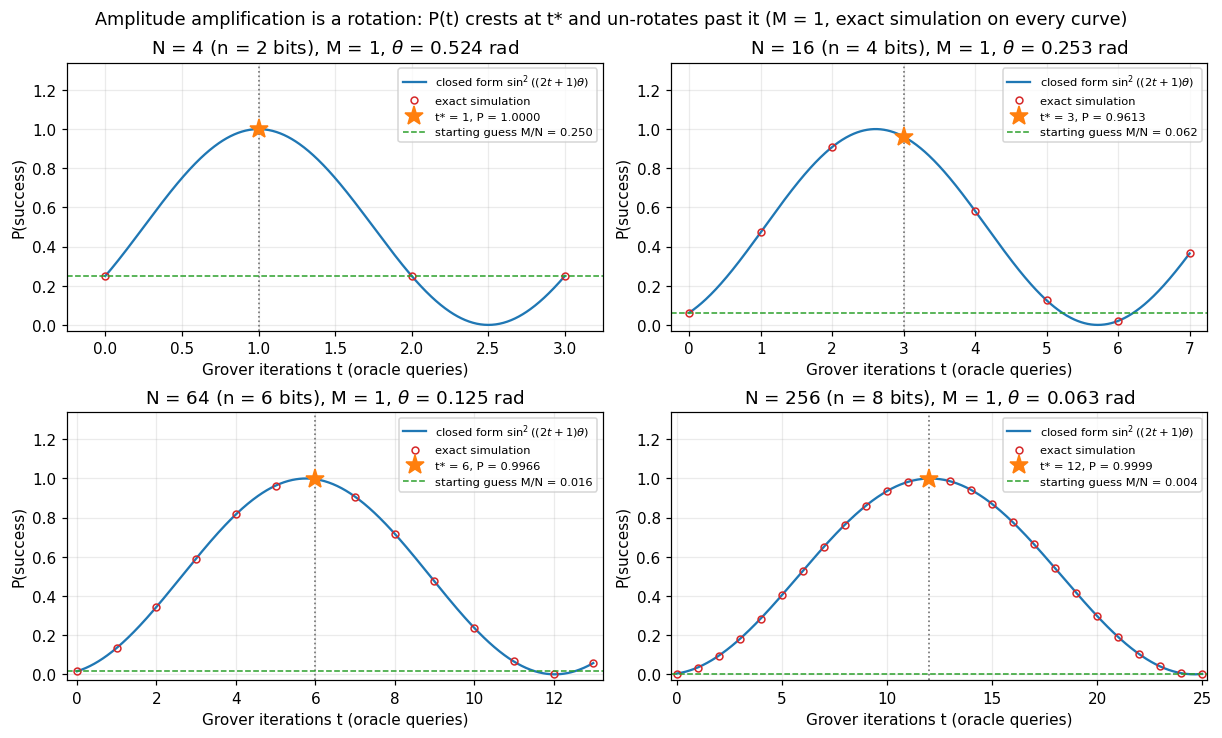

In [9]:

FIG1_CASES = [(4, 1), (16, 1), (64, 1), (256, 1)]
fig1, axes1 = plt.subplots(2, 2, figsize=(11, 6.6), dpi=110, constrained_layout=True)
for ax, (N, M) in zip(axes1.ravel(), FIG1_CASES):
    ts = optimal_t(N, M)
    tmax = 2 * ts + 1
    tg = np.linspace(0, tmax, 600)
    ax.plot(tg, [closed_form_p(tt, M, N) for tt in tg], lw=1.5, color="C0",
            label="closed form $\\sin^2((2t+1)\\theta)$")
    ax.plot(range(tmax + 1), [CLOSED[(N, M)]["curve"][t] for t in range(tmax + 1)], "o", ms=4.5,
            color="C3", mfc="none", label="exact simulation")
    p_star = CLOSED[(N, M)]["p_star"]
    ax.axvline(ts, color="0.45", ls=":", lw=1.1)
    ax.plot([ts], [p_star], marker="*", ms=13, color="C1", ls="",
            label=f"t* = {ts}, P = {p_star:.4f}")
    ax.axhline(M / N, color="C2", ls="--", lw=1.0, label=f"starting guess M/N = {M / N:.3f}")
    ax.set_title(f"N = {N} (n = {int(round(math.log2(N)))} bits), M = {M}, "
                 f"$\\theta$ = {theta_of(M, N):.3f} rad")
    ax.set_xlabel("Grover iterations t (oracle queries)")
    ax.set_ylabel("P(success)")
    ax.set_ylim(-0.03, 1.34)
    ax.set_xlim(-0.25, tmax + 0.25)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", fontsize=7.5)
fig1.suptitle("Amplitude amplification is a rotation: P(t) crests at t* and un-rotates past it "
              "(M = 1, exact simulation on every curve)", fontsize=11.5)
save_figure(fig1, "fig1_p_vs_iterations")
plt.show()


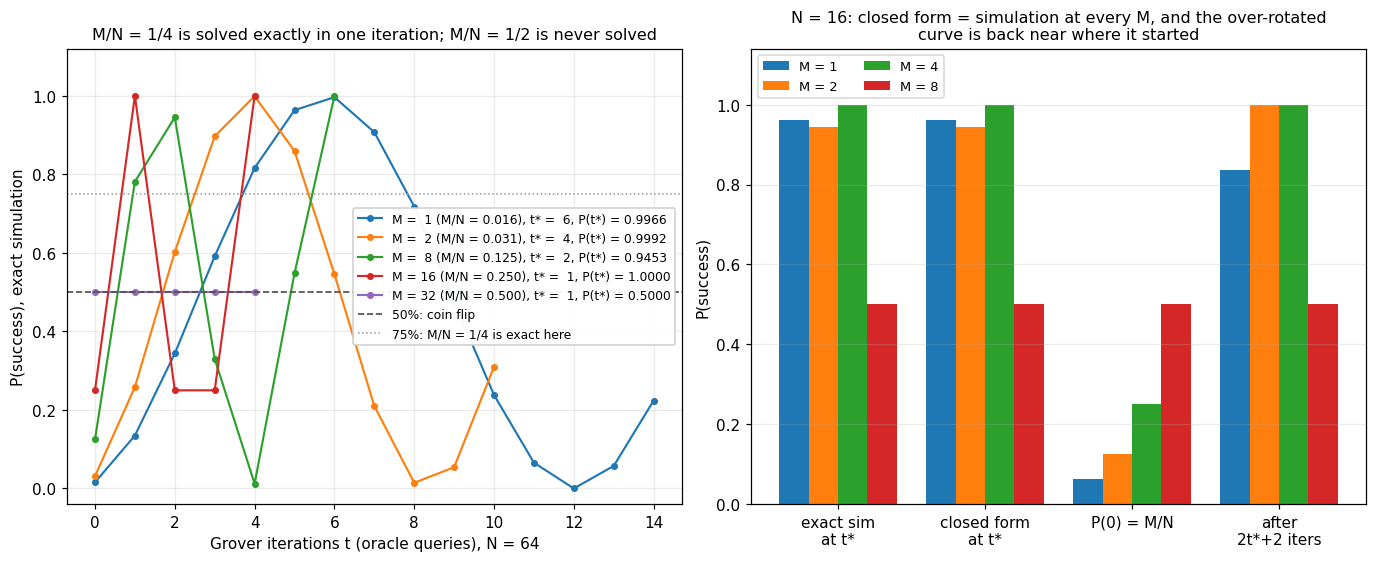

In [10]:

FIG2_CASES = [(64, 1), (64, 2), (64, 8), (64, 16), (64, 32)]
FIG3_CASES = [(16, 1), (16, 2), (16, 4), (16, 8)]
fig2, (ax2, ax3) = plt.subplots(1, 2, figsize=(12.4, 5.0), dpi=110, constrained_layout=True)
for (N, M), colour in zip(FIG2_CASES, ("C0", "C1", "C2", "C3", "C4")):
    n = int(round(math.log2(N)))
    marked = CSP_SETS[(N, M)]["marked"]
    ts = optimal_t(N, M)
    curve = simulate_p_curve(n, marked, 2 * ts + 2)
    ax2.plot(range(len(curve)), curve, "-o", ms=3.6, lw=1.4, color=colour,
             label=f"M = {M:>2} (M/N = {M / N:.3f}), t* = {ts:>2}, P(t*) = {curve[ts]:.4f}")
ax2.axhline(0.5, color="0.3", ls="--", lw=1.1, label="50%: coin flip")
ax2.axhline(0.75, color="0.6", ls=":", lw=1.0, label="75%: M/N = 1/4 is exact here")
ax2.set_xlabel("Grover iterations t (oracle queries), N = 64")
ax2.set_ylabel("P(success), exact simulation")
ax2.set_ylim(-0.04, 1.12)
ax2.set_title("M/N = 1/4 is solved exactly in one iteration; M/N = 1/2 is never solved", fontsize=10.5)
ax2.grid(alpha=0.25)
ax2.legend(loc="center right", fontsize=8, framealpha=0.95)

width = 0.2
for i, (N, M) in enumerate(FIG3_CASES):
    n = int(round(math.log2(N)))
    marked = CSP_SETS[(N, M)]["marked"]
    ts = optimal_t(N, M)
    vals = [sim_p_at(n, marked, ts), closed_form_p(ts, M, N), M / N,
            simulate_p_curve(n, marked, 2 * ts + 2)[2 * ts + 2]]
    ax3.bar(np.arange(4) + (i - 1.5) * width, vals, width=width, label=f"M = {M}")
ax3.set_xticks(range(4))
ax3.set_xticklabels(["exact sim\nat t*", "closed form\nat t*", "P(0) = M/N", "after\n2t*+2 iters"])
ax3.set_ylabel("P(success)")
ax3.set_ylim(0, 1.14)
ax3.set_title("N = 16: closed form = simulation at every M, and the over-rotated\ncurve is back near where it started", fontsize=10.5)
ax3.grid(alpha=0.25, axis="y")
ax3.legend(loc="upper left", fontsize=8.5, ncol=2)
save_figure(fig2, "fig2_M_family_and_closed_form_bars")
plt.show()



---
## Part 5 · The 3-qubit search, amplitude by amplitude

`n = 3`, `N = 8`, the subset-sum instance of Part 1 (`weights = (3, 4, 5)`, `target = 8`), so the
marked set is `|101⟩` with `M = 1` and `θ = arcsin(1/√8) = 0.361367 rad`. `t* = 2`.

The table below prints, for every iteration, the amplitude of the marked state, the (all equal)
amplitude of the seven unmarked states, `P = |a_m|²`, and the norm. Two things to watch:

* The unmarked amplitude **changes sign at the peak**: after `t*` the marked amplitude decreases
  while the unmarked one grows in magnitude — the over-rotation is visible in the unmarked
  channel, which is exactly the quantity Part 7's noise model destroys first.
* Symmetry is not assumed, it is checked: all seven unmarked amplitudes stay equal because
  `O_f` and `D` are both constant on the unmarked set. That is why the whole algorithm lives in
  a 2-dimensional plane inside an 8-dimensional space.

Headline for this part: the 3-qubit single-marked search reaches `P = 0.945312` at `t* = 2` — the
`1.000000` you see in Part 4 belongs to the `M/N = 1/4` family, e.g. `N = 4, M = 1` at `t = 1`,
because a single marked item with `N = 8` cannot land exactly on `π/2`.


In [11]:

ex_n, ex_marked = 3, INSTANCES["subset-sum n=3"]["marked"]
ex_M, ex_N = len(ex_marked), 8
Oex, Dex = phase_oracle_matrix(ex_n, ex_marked), diffusion_matrix(ex_n)
psi = uniform_state(ex_n)
EX_ROWS = []
print(f"n = 3, marked {[''.join(map(str, bits_of(x, 3))) for x in ex_marked]}, "
      f"theta = {theta_of(ex_M, ex_N):.6f} rad, t* = {optimal_t(ex_N, ex_M)}")
print(f"{'t':>2} {'a[marked]':>18} {'a[unmarked]':>18} {'P(marked)':>11} {'P(one unmarked)':>16} "
      f"{'closed form':>12} {'norm':>18}")
for t in range(5):
    a_m = psi[ex_marked[0]]
    a_u = psi[[x for x in range(8) if x not in ex_marked][0]]
    print(f"{t:>2} {a_m.real:>11.6f}{a_m.imag:+7.1e}j {a_u.real:>11.6f}{a_u.imag:+7.1e}j "
          f"{abs(a_m) ** 2:>11.6f} {abs(a_u) ** 2:>16.6f} "
          f"{closed_form_p(t, ex_M, ex_N):>12.6f} {np.linalg.norm(psi):>18.14f}")
    EX_ROWS.append(psi.copy())
    psi = Dex @ (Oex @ psi)

print(f"\nall 8 amplitudes at each iteration (real parts x 1000):")
for t, row in enumerate(EX_ROWS):
    print(f"  t = {t}: " + "  ".join(f"{''.join(map(str, bits_of(x, 3)))}"
                                     f"{row[x].real * 1000:>+7.1f}" for x in range(8)))
print("\nunmarked amplitude |a_u| by iteration:",
      [f"{abs(EX_ROWS[t][0]):.6f}" for t in range(5)],
      " (grows once past t* = 2 -> over-rotation)")

SHOTS_LIST = [256, 1024, 4096, 16384]
print(f"\nfinite shots from the exact distribution of the n = 3 instance (rng seeded with SEED):")
print(f"{'t':>2} {'P_exact':>9} " + " ".join(f"{s:>10}d shots" for s in SHOTS_LIST))
for t in range(4):
    probs = np.abs(EX_ROWS[t]) ** 2
    probs = probs / probs.sum()
    row = []
    for shots in SHOTS_LIST:
        counts = rng.multinomial(shots, probs)
        row.append(f"{counts[ex_marked[0]] / shots:>10.4f}")
    print(f"{t:>2} {probs[ex_marked[0]]:>9.4f} " + " ".join(row))
print("(the 256-shot column wanders; the 16384-shot column is within statistical error of the "
      "exact value, and error shrinks like 1/sqrt(shots))")


n = 3, marked ['101'], theta = 0.361367 rad, t* = 2
 t          a[marked]        a[unmarked]   P(marked)  P(one unmarked)  closed form               norm
 0    0.353553+0.0e+00j    0.353553+0.0e+00j    0.125000         0.125000     0.125000   1.00000000000000
 1    0.883883+0.0e+00j    0.176777+0.0e+00j    0.781250         0.031250     0.781250   1.00000000000000
 2    0.972272+0.0e+00j   -0.088388+0.0e+00j    0.945312         0.007813     0.945312   1.00000000000000
 3    0.574524+0.0e+00j   -0.309359+0.0e+00j    0.330078         0.095703     0.330078   1.00000000000000
 4   -0.110485+0.0e+00j   -0.375650+0.0e+00j    0.012207         0.141113     0.012207   1.00000000000000

all 8 amplitudes at each iteration (real parts x 1000):
  t = 0: 000 +353.6  001 +353.6  010 +353.6  011 +353.6  100 +353.6  101 +353.6  110 +353.6  111 +353.6
  t = 1: 000 +176.8  001 +176.8  010 +176.8  011 +176.8  100 +176.8  101 +883.9  110 +176.8  111 +176.8
  t = 2: 000  -88.4  001  -88.4  010  -88.4  011  -

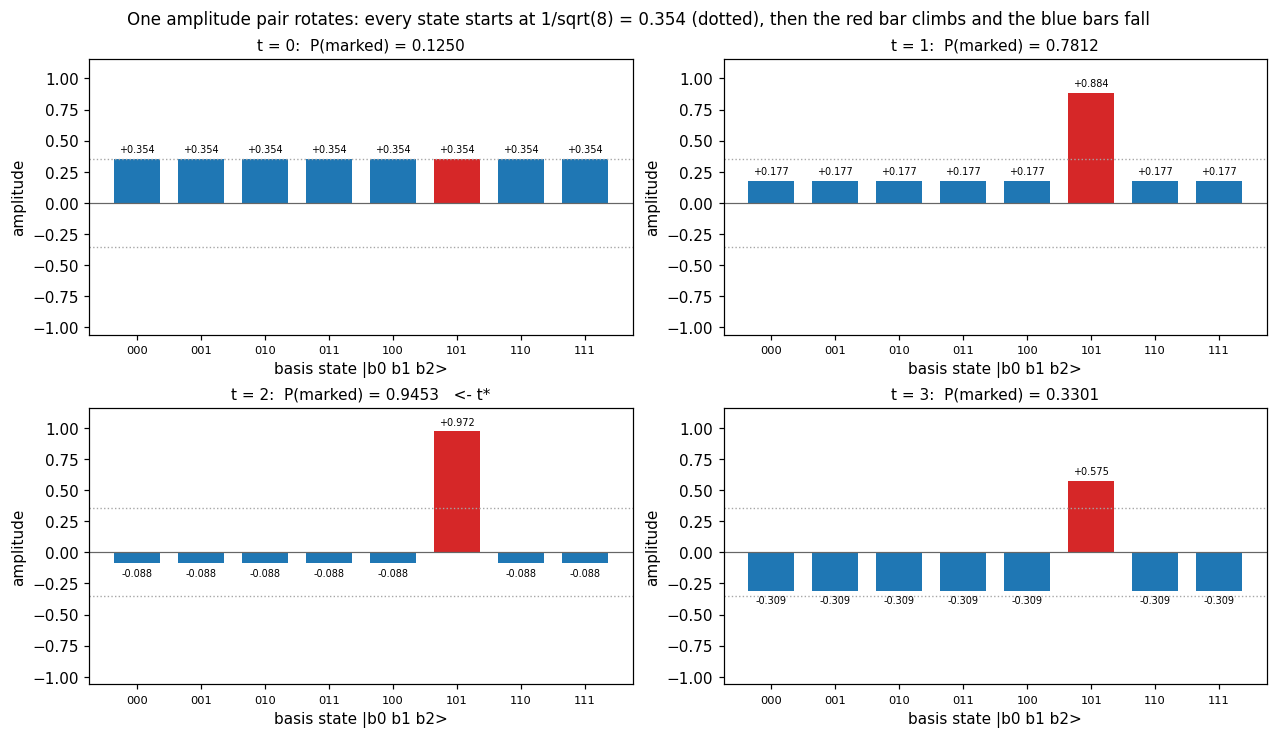

In [12]:

fig4, axes4 = plt.subplots(2, 2, figsize=(11.5, 6.6), dpi=110, constrained_layout=True)
a0 = 1 / math.sqrt(8)
for t, ax in enumerate(axes4.ravel()):
    amps = np.real(EX_ROWS[t])
    ax.bar(range(8), amps, width=0.72,
           color=["C3" if x in ex_marked else "C0" for x in range(8)])
    for x in range(8):
        ax.annotate(f"{amps[x]:+.3f}", (x, amps[x] + (0.05 if amps[x] >= 0 else -0.10)),
                    ha="center", fontsize=6.4)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.axhline(a0, color="0.65", ls=":", lw=0.9)
    ax.axhline(-a0, color="0.65", ls=":", lw=0.9)
    ax.set_xticks(range(8))
    ax.set_xticklabels(["".join(map(str, bits_of(x, 3))) for x in range(8)], fontsize=7.5)
    ax.set_xlabel("basis state |b0 b1 b2>")
    ax.set_ylabel("amplitude")
    ax.set_ylim(-1.06, 1.16)
    ax.set_title(f"t = {t}:  P(marked) = {abs(EX_ROWS[t][ex_marked[0]]) ** 2:.4f}"
                 + ("   <- t*" if t == optimal_t(8, 1) else ""), fontsize=10)
fig4.suptitle("One amplitude pair rotates: every state starts at 1/sqrt(8) = 0.354 (dotted), "
              "then the red bar climbs and the blue bars fall", fontsize=11)
save_figure(fig4, "fig4_three_qubit_steps")
plt.show()


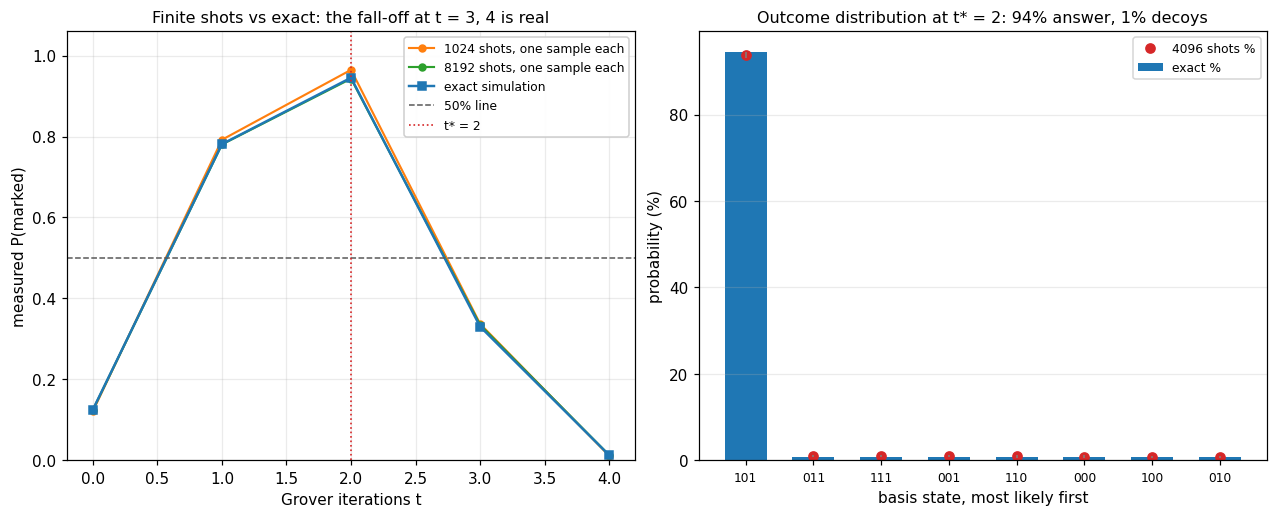

In [13]:

fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=110, constrained_layout=True)
ts3 = optimal_t(8, 1)
exact_probs = [np.abs(EX_ROWS[t]) ** 2 for t in range(5)]
for shots, colour in ((1024, "C1"), (8192, "C2")):
    stream = np.random.default_rng(SEED + shots)
    measured = []
    for t in range(5):
        p = exact_probs[t] / exact_probs[t].sum()
        measured.append(stream.multinomial(shots, p)[ex_marked[0]] / shots)
    ax5a.plot(range(5), measured, "-o", ms=4.5, lw=1.4, color=colour,
              label=f"{shots} shots, one sample each")
ax5a.plot(range(5), [p[ex_marked[0]] for p in exact_probs], "-s", ms=5, lw=1.6, color="C0",
          label="exact simulation")
ax5a.axhline(0.5, color="0.35", ls="--", lw=1.0, label="50% line")
ax5a.axvline(ts3, color="C3", ls=":", lw=1.1, label="t* = 2")
ax5a.set_xlabel("Grover iterations t")
ax5a.set_ylabel("measured P(marked)")
ax5a.set_ylim(0, 1.06)
ax5a.set_title("Finite shots vs exact: the fall-off at t = 3, 4 is real", fontsize=10.5)
ax5a.grid(alpha=0.25)
ax5a.legend(loc="upper right", fontsize=8, framealpha=0.95)

probs8 = exact_probs[ts3] / exact_probs[ts3].sum()
stream = np.random.default_rng(SEED + 4096)
counts = stream.multinomial(4096, probs8)
labels = ["".join(map(str, bits_of(x, 3))) for x in range(8)]
order = np.argsort(-counts)
ax5b.bar(range(8), probs8[order] * 100, width=0.62, color="C0", label="exact %")
ax5b.plot(range(8), counts[order] / 4096 * 100, "o", ms=6, color="C3",
          label="4096 shots %")
for k, x in enumerate(order):
    err = 1.96 * math.sqrt(max(probs8[x], 1e-9) * (1 - probs8[x]) / 4096) * 100
    ax5b.errorbar(k, counts[x] / 4096 * 100, yerr=err, fmt="none", ecolor="0.5", lw=1.0)
ax5b.set_xticks(range(8))
ax5b.set_xticklabels([labels[x] for x in order], fontsize=8)
ax5b.set_xlabel("basis state, most likely first")
ax5b.set_ylabel("probability (%)")
ax5b.set_title("Outcome distribution at t* = 2: 94% answer, 1% decoys", fontsize=10.5)
ax5b.grid(alpha=0.25, axis="y")
ax5b.legend(loc="upper right", fontsize=8)
save_figure(fig5, "fig5_shots_vs_exact")
plt.show()



---
## Part 6 · Query complexity: what `O(sqrt(N))`) actually buys

Grover uses `t*` oracle calls to reach `P(t*) ≈ 1`; the best classical strategy for an
unstructured predicate needs `N/2` calls for a 50% chance and `(N+1)/2` on average to *find* the
hit (`N/(2M)` and `(N+1)/(2M)` for `M` hits). Setting `P(t) = 1/2` gives the queries needed for a
coin-flip answer:

$$t_{50} = \left\lceil \frac{\pi}{8\theta} - \frac12 \right\rceil \approx \frac{\pi}{8}\sqrt{\frac NM}$$

so on a log-log plot the quantum line has slope `1/2` and the classical line slope `1`. The fit
below is measured on the closed form, not assumed.

**This is optimal, and it is a theorem.** Bennett–Bernstein–Brassard–Vazirani (BBBV, 1997) prove
that *any* quantum algorithm that finds a marked item with probability `≥ 1/3` needs
`Ω(√(N/M))` oracle queries. Grover is within a constant factor of the ceiling: there is no
cleverer oracle, no better schedule, no entangled trick that makes search classical-to-square-root
faster than square-root. The `π/4` in `t*` is the price of quantum mechanics, not of a bad
algorithm — which is also why the practical wins come from making the *oracle* cheap, not from
counting qubits.


In [14]:

def queries_to(N, M, frac=0.5, tmax=10**7):
    """Oracle calls (= Grover iterations) needed before P(t) first reaches frac."""
    t = 0
    while closed_form_p(t, M, N) < frac:
        t += 1
        if t > tmax:
            raise RuntimeError("should not happen")
    return t


def classical_queries(N, M, frac=0.5):
    """Random sampling without replacement: P = k*M/N after k distinct guesses."""
    return math.ceil(frac * N / M)


NQ = [4, 16, 64, 256, 1024, 4096, 65536, 262144, 1048576]
print("M = 1 instances; 'queries' counts oracle calls only (the diffusion's O(n) gates are free "
      "in this model, which is exactly why Part 7 matters)")
print(f"{'N':>9} {'n':>3} {'t*':>4} {'P(t*)':>9} {'t50':>5} {'classical t50':>14} "
      f"{'speedup':>9} {'classical avg':>14}")
rows = []
for N in NQ:
    n = math.log2(N)
    ts = optimal_t(N, 1)
    q50 = queries_to(N, 1)
    c50 = classical_queries(N, 1)
    rows.append((N, ts, closed_form_p(ts, 1, N), q50, c50))
    print(f"{N:>9} {n:>3.0f} {ts:>4} {closed_form_p(ts, 1, N):>9.6f} {q50:>5} {c50:>14} "
          f"{c50 / max(q50, 1)::>8.1f}x {(N + 1) / 2:>14.1f}")
N, M = 10**6, 1
print(f"{N:>9} {'~19.9':>3} {optimal_t(N, M):>4} {closed_form_p(optimal_t(N, M), M, N):>9.6f} "
      f"{queries_to(N, M):>5} {classical_queries(N, M):>14} "
      f"{classical_queries(N, M) / queries_to(N, M):>8.1f}x {(N + 1) / 2:>14.1f}")

for M in (2, 8, 64):
    N = 65536
    print(f"N = {N}, M = {M:>3}: t* = {optimal_t(N, M):>4}, P(t*) = {closed_form_p(optimal_t(N, M), M, N):.6f}, "
          f"t50 = {queries_to(N, M):>4}, classical t50 = {classical_queries(N, M)}")

xs, ys = np.array([math.log10(N) for N, *_ in rows]), np.array([math.log10(max(r[3], 1)) for r in rows])
fit_all = np.polyfit(xs, ys, 1)
fit_tail = np.polyfit(xs[2:], ys[2:], 1)
cls_slope = np.polyfit(xs, np.array([math.log10(r[4]) for r in rows]), 1)[0]
print(f"\nlog-log fit of quantum queries-to-50%-success vs N (N = 4 .. {NQ[-1]}): "
      f"slope = {fit_all[0]:.4f}  (theory 0.5, |err| = {abs(fit_all[0] - 0.5):.4f})")
print(f"  drop the two smallest N: slope = {fit_tail[0]:.4f}")
print(f"  classical random search, same fit: slope = {cls_slope:.4f}")
print(f"  intercept: log10(queries) = {fit_all[0]:.4f} log10(N) {fit_all[1]:+.4f} "
      f"-> queries ~ {10 ** fit_all[1]:.2f} sqrt(N)   (asymptotic constant pi/4 = {math.pi / 4:.4f})")
SLOPE_QUANTUM = float(fit_all[0])


M = 1 instances; 'queries' counts oracle calls only (the diffusion's O(n) gates are free in this model, which is exactly why Part 7 matters)
        N   n   t*     P(t*)   t50  classical t50   speedup  classical avg
        4   2    1  1.000000     1              2 :::::2.0x            2.5
       16   4    3  0.961319     2              8 :::::4.0x            8.5
       64   6    6  0.996586     3             32 ::::10.7x           32.5
      256   8   12  0.999947     6            128 ::::21.3x          128.5
     1024  10   25  0.999461    13            512 ::::39.4x          512.5
     4096  12   50  0.999945    25           2048 ::::81.9x         2048.5
    65536  16  201  0.999988   101          32768 :::324.4x        32768.5
   262144  18  402  0.999998   201         131072 :::652.1x       131072.5
  1048576  20  804  1.000000   402         524288 ::1304.2x       524288.5
  1000000 ~19.9  785  1.000000   393         500000   1272.3x       500000.5
N = 65536, M =   2: t* =  142, P

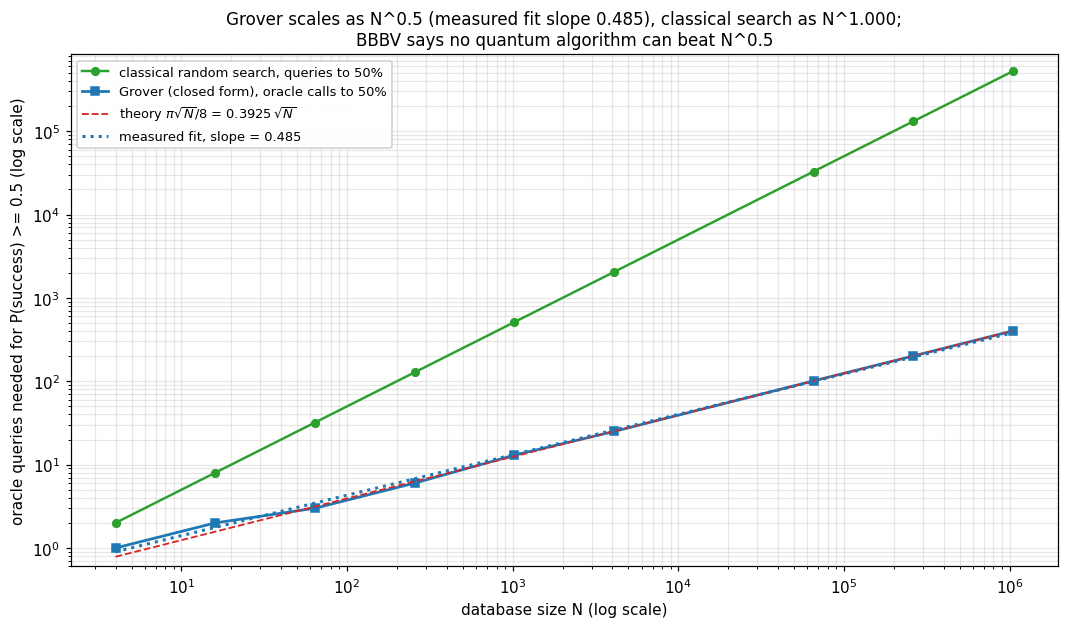

In [15]:

fig6, ax6 = plt.subplots(figsize=(9.6, 5.6), dpi=110, constrained_layout=True)
Ns = np.array([r[0] for r in rows], dtype=float)
q50 = np.array([r[3] for r in rows], dtype=float)
c50 = np.array([r[4] for r in rows], dtype=float)
ax6.loglog(Ns, c50, "-o", ms=5, lw=1.6, color="C2", label="classical random search, queries to 50%")
ax6.loglog(Ns, q50, "-s", ms=5, lw=1.8, color="C0", label="Grover (closed form), oracle calls to 50%")
ax6.loglog(Ns, np.pi / 8 * np.sqrt(Ns), "--", lw=1.2, color="C3",
           label="theory $\\pi\\sqrt{N}/8$ = $0.3925\\,\\sqrt{N}$")
xs_l = np.log10(Ns)
ax6.loglog(10 ** xs_l, 10 ** (SLOPE_QUANTUM * xs_l + np.polyfit(xs_l, np.log10(q50), 1)[1]),
           ":", lw=2.0, color="C0",
           label=f"measured fit, slope = {SLOPE_QUANTUM:.3f}")
ax6.set_xlabel("database size N (log scale)")
ax6.set_ylabel("oracle queries needed for P(success) >= 0.5 (log scale)")
ax6.set_title("Grover scales as N^0.5 (measured fit slope %.3f), classical search as N^1.000;"
              "\nBBBV says no quantum algorithm can beat N^0.5" % SLOPE_QUANTUM, fontsize=11)
ax6.grid(alpha=0.3, which="both")
ax6.legend(loc="upper left", fontsize=8.5, framealpha=0.95)
ax6.set_ylim(0.6, max(c50) * 1.6)
save_figure(fig6, "fig6_query_complexity")
plt.show()



---
## Part 7 · Noise: one query is one gate, the diffusion is dozens

Query complexity counts oracle calls and pretends the diffusion is free. It is not: `D` costs `2n`
Hadamards, `2n` bit flips and one `C^{n-1}Z`, which compiles ancilla-free (Barenco et al. 1995)
into `2(n-1)-3` two-qubit gates — `6n-5` elementary operations per iteration (37 at `n = 7`)
against a single oracle call, and CNOTs are the noisiest operation on real devices.

**Model, stated explicitly.** A density matrix `rho` of shape `(2ⁿ, 2ⁿ)`, updated gate by gate.
After each gate on qubit set `Q` we apply, to every `q ∈ Q` independently, the single-qubit
depolarising channel of strength `p` in Kraus form: with probability `p` one uniformly random Pauli
is applied instead of the identity,

$$\rho \longmapsto \left(1-\tfrac{3p}{4}\right)\rho + \frac{p}{4}\sum_{\sigma \in \{X,Y,Z\}} \sigma\rho\,\sigma$$

so `p = 1` is exactly the maximally mixed qubit. A gate that compiles to `c` elementary operations
is charged `1-(1-p)^c` rather than `p`, which is why a CNOT (2 qubits) is degraded twice as much as
a Hadamard and the `C^{n-1}Z` more than anything else on the register. The oracle is kept **exact**
(that is the honest reading of "we pay one query, we get a clean answer"), and `p = 0` reproduces
Part 4's noiseless curve to ~1e-14, which is the test that the machinery is right.

Trace and positivity are preserved by construction; what is lost is the *coherence between the
marked and unmarked amplitudes*, which is the entire resource. Since `D` is the only place the
state's phase structure is used, depolarising `D` is depolarising the algorithm.


In [16]:

def left_apply(T, A, axis):
    """Apply the 2x2 matrix A along one rank-2 axis of a tensor."""
    Mv = np.moveaxis(T, axis, 0)
    out = (A @ Mv.reshape(2, -1)).reshape(Mv.shape)
    return np.moveaxis(out, 0, axis)


def apply_operator_to_rho(rho, U, qs, n):
    """rho -> U rho U^dagger, U acting on the qubits in qs (qs[0] = U's most significant index)."""
    k = len(qs)
    T = rho.reshape([2] * (2 * n))
    T = np.moveaxis(T, qs, list(range(k)))
    T = (U @ T.reshape(2**k, -1)).reshape([2] * k + [2] * (2 * n - k))
    T = np.moveaxis(T, list(range(k)), qs)
    cols = [n + q for q in qs]
    T = np.moveaxis(T, cols, list(range(k)))
    T = (U.conj() @ T.reshape(2**k, -1)).reshape([2] * k + [2] * (2 * n - k))
    T = np.moveaxis(T, list(range(k)), cols)
    return T.reshape(2**n, 2**n)


def depolarize(rho, q, n, p):
    """Single-qubit depolarising channel in the Pauli-probability convention: with probability p a
    uniformly random Pauli is applied instead of the identity, i.e.
    rho -> (1 - 3p/4) rho + (p/4)(X rho X + Y rho Y + Z rho Z).
    Kraus set sqrt(1 - 3p/4) I and sqrt(p/4) X, Y, Z, which is trace preserving for every p and
    gives the maximally mixed qubit at p = 1."""
    if p <= 0.0:
        return rho
    out = (1 - 0.75 * p) * rho
    for K in (X, Y, Z):
        out = out + (p / 4) * apply_operator_to_rho(rho, K, [q], n)
    return out


def compiled_cost(qubits):
    """Elementary-operation cost of one gate: single-qubit = 1, CNOT = 1, and a C^{k}Z on k+1
    qubits = 2k-3 two-qubit gates (Barenco et al. 1995, ancilla-free multi-controlled synthesis)."""
    k = len(qubits)
    if k <= 2:
        return 1
    return 2 * (k - 1) - 3


def noisy_grover(n, marked, tmax, p):
    """Density-matrix Grover: noiseless oracle, then each diffusion gate followed by the
    depolarising channel on every qubit it touches, at the compounded strength 1-(1-p)^cost.
    Returns (P(t) curve, purity curve, channels applied per iteration, probability that at least
    one of those channels fires in a single iteration)."""
    marked = list(marked)
    psi = uniform_state(n)
    rho = np.outer(psi, psi.conj())
    O = phase_oracle_matrix(n, marked)
    Dops = diffusion_circuit(n).ops

    def success(r):
        return float(np.real(np.trace(r[np.ix_(marked, marked)])))

    probs, purities = [success(rho)], [float(np.real(np.trace(rho @ rho)))]
    # one iteration applies one channel per qubit per diffusion gate, at the compounded strength
    strengths = [1 - (1 - p) ** compiled_cost(qs) for _, qs, _ in Dops for _ in qs]
    err_per_iter = 1.0 - float(np.prod([1.0 - s for s in strengths]))
    channels_per_iter = len(strengths)
    for _ in range(tmax):
        rho = O @ rho @ O.conj()
        for _, qs, U in Dops:
            rho = apply_operator_to_rho(rho, U, qs, n)
            p_eff = 1 - (1 - p) ** compiled_cost(qs)
            for q in qs:
                rho = depolarize(rho, q, n, p_eff)
        probs.append(success(rho))
        purities.append(float(np.real(np.trace(rho @ rho))))
    return probs, purities, channels_per_iter, err_per_iter


NOISE_N, NOISE_M = 7, 1
noise_weights, noise_target, NOISE_MARKED, _noise_how = subset_sum_instance(
    NOISE_N, NOISE_M, np.random.default_rng(SEED + 405))
NOISE_PS = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.02]
NOISE_TMAX = 16
clean_curve = simulate_p_curve(NOISE_N, NOISE_MARKED, NOISE_TMAX)
ts_noise = optimal_t(2**NOISE_N, NOISE_M)
Dops_show = diffusion_circuit(NOISE_N).ops
n_elementary = sum(compiled_cost(qs) for _, qs, _ in Dops_show)
print(f"n = {NOISE_N} (N = {2 ** NOISE_N}), M = 1, weights {noise_weights}, target {noise_target}")
print(f"diffusion = {len(Dops_show)} circuit operations -> {n_elementary} elementary operations "
      f"per iteration, of which {sum(len(qs) for _, qs, _ in Dops_show)} qubit-channels get "
      f"depolarised (noiseless t* = {ts_noise}, P(t*) = {clean_curve[ts_noise]:.6f})")
print(f"{'p per gate':>11} {'error/iter':>11} {'peak t':>7} {'P(peak)':>9} {'P(t*)':>8} "
      f"{'t with P>=0.5':>14} {'purity at t*':>13} {'beats coin flip?':>17}")
NOISE = {}
for p in NOISE_PS:
    probs, purities, n_channels, err_iter = noisy_grover(NOISE_N, NOISE_MARKED, NOISE_TMAX, p)
    peak_t = int(np.argmax(probs))
    depth = sum(1 for v in probs if v >= 0.5)
    NOISE[p] = dict(probs=probs, purities=purities, peak_t=peak_t, peak=probs[peak_t],
                    n_elementary=n_elementary, n_channels=n_channels, err_iter=err_iter,
                    depth=depth)
    print(f"{p:>11.4f} {err_iter:>11.4f} {peak_t:>7} {probs[peak_t]:>9.6f} {probs[ts_noise]:>8.6f} "
          f"{depth:>14} {purities[ts_noise]:>13.6f} "
          f"{'yes' if probs[peak_t] > 0.5 + 1e-9 else 'NO':>17}")
print(f"\nsanity: p = 0 reproduces the exact state-vector curve to "
      f"{max(abs(NOISE[0.0]['probs'][t] - clean_curve[t]) for t in range(NOISE_TMAX + 1)):.1e}")
print(f"reading the table: the noiseless recipe wants t* = {ts_noise} iterations; the depth the "
      f"hardware can actually support is the 'peak t' column, and Grover is only worth running "
      f"while P(peak) stays above 0.5.")


n = 7 (N = 128), M = 1, weights (7, 11, 9, 13, 6, 10, 5), target 14
diffusion = 29 circuit operations -> 37 elementary operations per iteration, of which 35 qubit-channels get depolarised (noiseless t* = 8, P(t*) = 0.995620)
 p per gate  error/iter  peak t   P(peak)    P(t*)  t with P>=0.5  purity at t*  beats coin flip?
     0.0000      0.0000       8  0.995620 0.995620              9      1.000000               yes
     0.0005      0.0445       8  0.813504 0.813504              7      0.669835               yes
     0.0010      0.0870       8  0.666771 0.666771              6      0.455081               yes
     0.0020      0.1666       7  0.467895 0.452314              0      0.220612                NO
     0.0050      0.3663       5  0.200172 0.153967              0      0.042049                NO
     0.0200      0.8409       2  0.033560 0.010274              0      0.008380                NO

sanity: p = 0 reproduces the exact state-vector curve to 2.1e-14
reading the table: the 

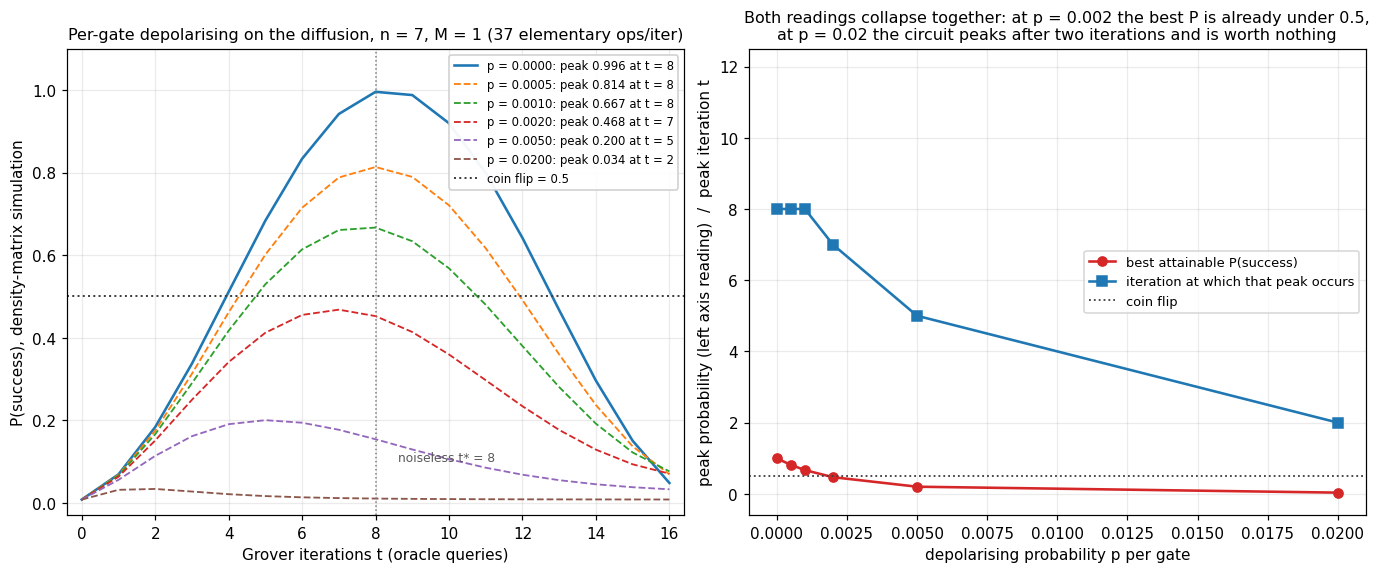

In [17]:

fig7, (ax7a, ax7b) = plt.subplots(1, 2, figsize=(12.4, 5.1), dpi=110, constrained_layout=True)
for p, colour in zip(NOISE_PS, ("C0", "C1", "C2", "C3", "C4", "C5")):
    probs = NOISE[p]["probs"]
    ax7a.plot(range(len(probs)), probs, "--" if p else "-",
              lw=1.7 if p == 0.0 else 1.2, color=colour,
              label=f"p = {p:.4f}: peak {NOISE[p]['peak']:.3f} at t = {NOISE[p]['peak_t']}")
ax7a.axhline(0.5, color="0.25", ls=":", lw=1.3, label="coin flip = 0.5")
ax7a.axvline(ts_noise, color="0.5", ls=":", lw=1.0)
ax7a.annotate(f"noiseless t* = {ts_noise}", (ts_noise + 0.6, 0.10), fontsize=8, color="0.35")
ax7a.set_xlabel("Grover iterations t (oracle queries)")
ax7a.set_ylabel("P(success), density-matrix simulation")
ax7a.set_ylim(-0.03, 1.10)
ax7a.set_xlim(-0.4, NOISE_TMAX + 0.4)
ax7a.set_title(f"Per-gate depolarising on the diffusion, n = {NOISE_N}, M = 1 "
               f"({n_elementary} elementary ops/iter)", fontsize=10.5)
ax7a.grid(alpha=0.25)
ax7a.legend(loc="upper right", fontsize=7.6, framealpha=0.95)

ax7b.plot(NOISE_PS, [NOISE[p]["peak"] for p in NOISE_PS], "-o", ms=6, lw=1.7, color="C3",
          label="best attainable P(success)")
ax7b.plot(NOISE_PS, [NOISE[p]["peak_t"] for p in NOISE_PS], "-s", ms=6, lw=1.7, color="C0",
          label="iteration at which that peak occurs")
ax7b.axhline(0.5, color="0.25", ls=":", lw=1.2, label="coin flip")
ax7b.set_xlabel("depolarising probability p per gate")
ax7b.set_ylabel("peak probability (left axis reading)  /  peak iteration t")
ax7b.set_ylim(-0.6, 12.5)
ax7b.set_title("Both readings collapse together: at p = 0.002 the best P is already under 0.5,\n"
               "at p = 0.02 the circuit peaks after two iterations and is worth nothing",
               fontsize=10.5)
ax7b.grid(alpha=0.25)
ax7b.legend(loc="center right", fontsize=8.5)
save_figure(fig7, "fig7_depolarising_noise")
plt.show()



---
## Part 8 · Self-tests

The checks that carry the argument: every gate matrix is unitary and involutory where it should
be; `HZH = X` and `(I⊗H)·CX·(I⊗H) = CZ`, which is why a **single**-control H-CNOT-H sandwich *is*
a `CZ` — and that the two-control chain is *not* a `CCZ` but a parity gate; the oracle built from
the **predicate** equals the oracle built from the **index list** for every instance; the
diffusion is a real symmetric orthogonal reflection with `det D = -1` for *every* `n` (including
odd `n`, where the `-1` survives because `2ⁿ − 1` is odd) and `D|s⟩ = +|s⟩`; the two diffusion
constructions agree to `1e-14` up to the documented global phase; the closed form equals the exact
simulation at every iteration for every `(N, M)` swept; `t*` really maximises it and `P(t)` is
monotone up to it; `M = N/2` is pinned at `0.5`; the `M/N = 1/4` family hits exactly `1.0`;
unmarked amplitudes shrink up to `t*`; norms stay `1`; the bit-flip oracle with a `|−⟩` work qubit
reproduces the phase oracle state for state; and the depolarising channel is trace-preserving,
reproduces the exact curve at `p = 0`, and never helps.


In [18]:

TESTS_PASSED, TESTS_FAILED = [], []


def check(name, cond):
    if bool(cond):
        TESTS_PASSED.append(name)
    else:
        TESTS_FAILED.append(name)
        print("  FAILED:", name)


def isc(a, b, tol=1e-10):
    return abs(a - b) <= tol


for gname, G in (("X", X), ("Y", Y), ("Z", Z), ("H", H)):
    check(f"{gname} is unitary", np.allclose(G @ G.conj().T, I2))
    check(f"{gname} is involutory", np.allclose(G @ G, I2))
check("HZH = X", np.allclose(H @ Z @ H, X))
check("HXH = Z", np.allclose(H @ X @ H, Z))
check("HYH = -Y", np.allclose(H @ Y @ H, -Y))
check("CNOT is unitary", np.allclose(CX @ CX.conj().T, np.eye(4)))
check("CNOT is involutory", np.allclose(CX @ CX, np.eye(4)))
check("CZ is symmetric", np.allclose(CZ, CZ.T))
check("CZ diagonal is 1,1,1,-1", np.allclose(np.diag(CZ).real, [1, 1, 1, -1]))
check("(I x H) CX (I x H) = CZ", np.allclose(np.kron(I2, H) @ CX @ np.kron(I2, H), CZ))
check("CX = CZ conjugated on the target", np.allclose(np.kron(I2, H) @ CZ @ np.kron(I2, H), CX))
check("one-control H-CNOT-H sandwich is exactly CZ",
      np.allclose(Circuit(2).chain_cz(0, 1).unitary(), CZ, atol=1e-14))
parity_chain = Circuit(3)
parity_chain.h(2)
parity_chain.cnot(0, 2)
parity_chain.cnot(1, 2)
parity_chain.h(2)
par = parity_chain.unitary()
ccz = Circuit(3).mcz([0, 1], 2).unitary()
check("the two-control CNOT chain is a parity gate, not CCZ",
      int(np.sum(np.diag(par).real < 0)) == 2 and not np.allclose(par, ccz))
check("exact C^2Z has a single -1, on |111>",
      int(np.sum(np.diag(ccz).real < 0)) == 1 and isc(ccz[7, 7].real, -1.0))
check("exact C^2Z is diagonal, unitary and involutory",
      np.allclose(np.abs(np.diag(ccz)), 1) and np.allclose(ccz @ ccz.conj().T, np.eye(8)))
tof = Circuit(3).mcp([0, 1], 2).unitary()
check("C^2X swaps |110> and |111> only",
      np.allclose(tof @ tof.conj().T, np.eye(8)) and int(np.argmax(tof[:, 6])) == 7
      and int(np.argmax(tof[:, 7])) == 6 and int(np.argmax(tof[:, 5])) == 5)
check("C^2X is not the parity chain", not np.allclose(tof, par @ np.diag([1, 1, 1, 1, 1, 1, -1, -1])))
check("kron order: X on qubit 0 of |00> is |10> (index 2)",
      np.allclose(np.kron(X, I2) @ zero_state(2), np.array([0, 0, 1, 0], dtype=complex)))
check("kron order: X on qubit 1 of |00> is |01> (index 1)",
      np.allclose(np.kron(I2, X) @ zero_state(2), np.array([0, 1, 0, 0], dtype=complex)))
for n in range(1, 6):
    check(f"uniform_state(n={n}) is normalised", isc(np.linalg.norm(uniform_state(n)), 1.0, 1e-14))
    check(f"zero_state(n={n}) is normalised", isc(np.linalg.norm(zero_state(n)), 1.0, 1e-14))
    check(f"apply_unitary preserves the norm at n={n}",
          isc(np.linalg.norm(apply_unitary(uniform_state(n), H, [n - 1], n)), 1.0, 1e-14))
check("bits_of round-trips every index at n=6",
      all(sum(b << (5 - q) for q, b in enumerate(bits_of(x, 6))) == x for x in range(64)))
check("bits_of matches format at n=5", all("".join(map(str, bits_of(x, 5))) == format(x, "05b")
                                          for x in range(32)))

for name, spec in INSTANCES.items():
    n, marked = spec["n"], spec["marked"]
    N, M = 2**n, spec["M"]
    Od = phase_oracle_matrix(n, marked)
    Oc = phase_oracle_circuit(n, marked).unitary()
    check(f"{name}: predicate matrix == index matrix oracle", np.allclose(Od, Oc, atol=1e-13))
    check(f"{name}: oracle is unitary", np.allclose(Od @ Od.conj().T, np.eye(N), atol=1e-13))
    check(f"{name}: oracle is hermitian", np.allclose(Od, Od.conj().T))
    check(f"{name}: oracle is its own inverse", np.allclose(Od @ Od, np.eye(N)))
    check(f"{name}: det(O) = (-1)^M", isc(np.linalg.det(Od).real, (-1) ** M, 1e-9))
    check(f"{name}: exactly M diagonal -1 entries", int(np.sum(np.diag(Od).real < 0)) == M)
    check(f"{name}: marked set is the brute-force predicate list",
          marked == brute_force(n, predicate_of(DATABASES[name])))

for N, M in SWEEP:
    n = int(round(math.log2(N)))
    rec = EXACT_SETS[(N, M)]
    check(f"subset-sum N={N},M={M}: predicate enumeration == vector-sum enumeration",
          rec["marked"] == brute_force(n, subset_sum_predicate(rec["weights"], rec["target"])))
    check(f"subset-sum N={N},M={M}: len(marked) == M", len(rec["marked"]) == M)
for (N, M), rec in CSP_SETS.items():
    check(f"CSP N={N},M={M}: brute force marks exactly M of N",
          len(rec["marked"]) == M and len(rec["marked"]) ==
          len(brute_force(rec["n"], clause_predicate(rec["clauses"], rec["n"]))))

for n in (2, 3, 4):
    marked = INSTANCES["subset-sum n=3"]["marked"] if n == 3 else [1]
    Uf = bit_flip_oracle_circuit(n, marked).unitary()
    dim = 2**(n + 1)
    check(f"bit-flip oracle n={n} is unitary", np.allclose(Uf @ Uf.conj().T, np.eye(dim)))
    check(f"bit-flip oracle n={n} is involutory", np.allclose(Uf @ Uf, np.eye(dim)))
    check(f"bit-flip oracle n={n} leaves |0..0>|0> alone", isc(abs(Uf[0, 0]), 1.0))
    flipped = np.kron(uniform_state(n), MINUS)
    out = Uf @ flipped
    want = np.kron(phase_oracle_matrix(n, marked) @ uniform_state(n), MINUS)
    check(f"bit-flip oracle on |s>|-> equals phase oracle on |s>, n={n}",
          np.allclose(out, want, atol=1e-13))
    blocks = out.reshape(2**n, 2)
    check(f"work qubit stays |-> after U_f, n={n}",
          np.allclose(blocks.conj().T @ blocks, np.outer(MINUS, MINUS.conj()), atol=1e-13))
    check(f"bit-flip simulation matches closed form at t=2, n={n}",
          isc(float(np.sum(simulate_bitflip(n, marked, 2)[marked])),
              closed_form_p(2, len(marked), 2**n), 1e-9))

for n in (1, 2, 3, 4):
    N = 2**n
    Dm = diffusion_matrix(n)
    check(f"D(n={n}) is unitary", np.allclose(Dm @ Dm.conj().T, np.eye(N)))
    check(f"D(n={n}) is real symmetric", np.allclose(Dm, Dm.T) and np.allclose(Dm.imag, 0))
    check(f"D(n={n}) squared is I", np.allclose(Dm @ Dm, np.eye(N), atol=1e-14))
    check(f"det D(n={n}) = -1", isc(np.linalg.det(Dm).real, -1.0, 1e-9))
    check(f"spectrum of D(n={n}) is one +1 and N-1 times -1",
          np.allclose(np.sort(np.linalg.eigvalsh(Dm)), [-1.0] * (N - 1) + [1.0], atol=1e-9))
    check(f"D(n={n}) fixes |s>", np.allclose(Dm @ uniform_state(n), uniform_state(n), atol=1e-14))
    check(f"D matrix == H^n (2|0><0|-I) H^n, n={n}", np.allclose(Dm, diffusion_algebraic(n), atol=1e-14))
    check(f"diffusion circuit == -(2|s><s|-I), n={n}",
          np.allclose(diffusion_circuit(n).unitary(), -Dm, atol=1e-14))
    check(f"diffusion circuit and diffusion matrix agree to 1e-14 up to global phase, n={n}",
          isc(abs(np.vdot(Dm.ravel(), diffusion_circuit(n).unitary().ravel())) / N, 1.0, 1e-12))
check("det D = -1 for odd n specifically",
      all(isc(np.linalg.det(diffusion_matrix(n)).real, -1.0, 1e-9) for n in (1, 3, 5)))
probe = rng.normal(size=16) + 1j * rng.normal(size=16)
probe /= np.linalg.norm(probe)
check("D acts as a_i -> 2<a> - a_i", np.allclose(diffusion_matrix(4) @ probe,
                                                 2 * np.mean(probe) - probe, atol=1e-12))
check("inversion_about_zero is diag(1,-1,...,-1)",
      np.allclose(np.diag(inversion_about_zero_matrix(3)).real, [1] + [-1] * 7))
check("H^n (2|0><0|-I) H^n == 2|s><s| - I at n=5",
      np.allclose(diffusion_algebraic(5), diffusion_matrix(5), atol=1e-14))
lifted = lift_to_register(diffusion_matrix(3), 3)
check("lift_to_register is unitary and hermitian",
      np.allclose(lifted @ lifted.conj().T, np.eye(16)) and np.allclose(lifted, lifted.conj().T))
check("lifted diffusion leaves the work qubit untouched",
      np.allclose(lifted @ np.kron(uniform_state(3), MINUS), np.kron(uniform_state(3), MINUS)))

for (N, M), rec in CLOSED.items():
    n = rec["n"]
    th = theta_of(M, N)
    tmax = len(rec["curve"]) - 1
    first_turn = int(math.floor((math.pi - th) / (2 * th)))     # last t with (2t+1)theta <= pi
    check(f"closed form == exact simulation for N={N}, M={M}",
          max(abs(rec["curve"][t] - closed_form_p(t, M, N)) for t in range(tmax + 1)) < 1e-12)
    check(f"t* is the best iteration count in the first turn for N={N}, M={M}",
          all(closed_form_p(rec["t_star"], M, N) >= closed_form_p(t, M, N) - 1e-12
              for t in range(first_turn + 1)))
    check(f"(2t*+1)theta is the closest approach to pi/2 for N={N}, M={M}",
          abs((2 * rec["t_star"] + 1) * th - math.pi / 2)
          <= min(abs((2 * t + 1) * th - math.pi / 2) for t in range(first_turn + 1)) + 1e-15)
    check(f"P(t) monotone non-decreasing up to t* for N={N}, M={M}",
          all(rec["curve"][t + 1] >= rec["curve"][t] - 1e-12 for t in range(rec["t_star"])))
    check(f"P(0) == M/N for N={N}, M={M}", isc(rec["curve"][0], M / N, 1e-12))
p8_long = [closed_form_p(t, 1, 8) for t in range(16)]
check("Grover is periodic: a later turn beats t* if you already know theta",
      max(p8_long) > p8_long[optimal_t(8, 1)] and max(p8_long) > 0.999)
check("M = N/2 dead end: closed form pinned at 0.5",
      all(isc(closed_form_p(t, DEAD["M"], 8), 0.5, 1e-12) for t in range(10)))
check("M = N/2 dead end: exact simulation pinned at 0.5",
      all(isc(DEAD["curve"][t], 0.5, 1e-12) for t in range(10)))
check("M = N/2: t* buys nothing", isc(closed_form_p(optimal_t(8, 4), 4, 8), 0.5, 1e-12))
check("CSP N = 64, M = 32 is also pinned at 0.5",
      all(isc(simulate_p_curve(6, CSP_SETS[(64, 32)]["marked"], 6)[t], 0.5, 1e-12) for t in range(7)))
check("M/N = 1/4 family gives exactly 1.0 at t = 1",
      all(isc(closed_form_p(1, M, N), 1.0, 1e-12) for N, M in ((4, 1), (8, 2), (16, 4), (32, 8))))
check("M/N = 1/4 family returns to 1.0 at t = 4",
      all(isc(closed_form_p(4, M, N), 1.0, 1e-12) for N, M in ((4, 1), (8, 2), (16, 4))))
check("M/N = 1/4 solved exactly by simulation too",
      isc(simulate_p_curve(4, CSP_SETS[(16, 4)]["marked"], 1)[1], 1.0, 1e-12))
check("theta(M = N/2) = pi/4", isc(theta_of(4, 8), math.pi / 4, 1e-14))
check("sin(theta) = sqrt(M/N) by construction",
      all(isc(math.sin(theta_of(M, N)), math.sqrt(M / N), 1e-14) for N, M in SWEEP))
check("optimal_t matches max(0, round((pi/4)sqrt(N/M) - 0.5))",
      all(optimal_t(N, M) == max(0, int(round((math.pi / 4) * math.sqrt(N / M) - 0.5)))
          for N, M in SWEEP))
unmarked_abs = [abs(EX_ROWS[t][0]) for t in range(3)]
check("unmarked amplitudes shrink after iteration 1 up to t*",
      unmarked_abs[1] < unmarked_abs[0] and unmarked_abs[2] < unmarked_abs[1])
check("3-qubit single-marked peak is 0.945312 at t* = 2",
      isc(EX_ROWS[2][5].real ** 2, 0.945312, 2e-6) and optimal_t(8, 1) == 2)
check("all unmarked amplitudes stay equal (the 2D-plane claim)",
      all(isc(abs(EX_ROWS[t][x]), abs(EX_ROWS[t][0]), 1e-13) for t in range(5)
          for x in range(8) if x not in ex_marked))
for n, tmax in ((3, 12), (4, 8), (6, 8)):
    marked = INSTANCES["subset-sum n=3"]["marked"] if n == 3 else EXACT_SETS[(2**n, 1)]["marked"]
    check(f"state stays normalised at every step, n={n}",
          all(isc(np.linalg.norm(grover_state(n, marked, t)), 1.0, 1e-12) for t in range(tmax + 1)))
Qm = grover_operator(3, ex_marked)
check("Grover operator Q = D O_f is unitary", np.allclose(Qm @ Qm.conj().T, np.eye(8), atol=1e-13))
check("Q from the circuit constructions == -Q from the matrices",
      np.allclose(grover_operator_from_circuits(3, ex_marked), -Qm, atol=1e-13))
mvec = np.zeros(8, dtype=complex)
mvec[ex_marked[0]] = 1.0
uvec = np.zeros(8, dtype=complex)
uvec[[x for x in range(8) if x not in ex_marked]] = 1 / math.sqrt(7)
after_q = Qm @ uniform_state(3)
basis = np.column_stack([mvec, uvec])
check("Q maps |s> into span{|m>, |u>}", np.linalg.norm(after_q - basis @ (basis.conj().T @ after_q)) < 1e-12)
check("one iteration rotates |s> by exactly 2 theta",
      isc(math.acos(float(np.real(np.vdot(uniform_state(3), after_q)))), 2 * theta_of(1, 8), 1e-9))

qs = [queries_to(N, 1) for N in NQ]
check("quantum queries to 50% are non-decreasing in N", all(b >= a for a, b in zip(qs, qs[1:])))
check("Grover beats classical queries for every N >= 16",
      all(queries_to(N, 1) < classical_queries(N, 1) for N in NQ if N >= 16))
check("classical queries to 50% equal N/2 for M = 1",
      all(classical_queries(N, 1) == N // 2 for N in NQ))
check("measured log-log slope within 0.05 of 0.5", abs(SLOPE_QUANTUM - 0.5) <= 0.05)
check("queries scale like sqrt(N): q(16N) ~ 4 q(N)",
      abs(queries_to(16 * 4096, 1) / queries_to(4096, 1) - 4.0) <= 0.5)
check("t50 is the first t with P >= 0.5",
      all(closed_form_p(queries_to(N, 1), 1, N) >= 0.5
          and closed_form_p(queries_to(N, 1) - 1, 1, N) < 0.5 for N in (256, 1024, 65536)))

p_k = 0.3
kraus_sum = (1 - 0.75 * p_k) * I2 + sum((p_k / 4) * (K.conj().T @ K) for K in (X, Y, Z))
check("depolarising Kraus set is trace preserving", np.allclose(kraus_sum, I2))
check("Kraus operators sum to a channel, p = 1 included",
      np.allclose((1 - 0.75) * I2 + sum(0.25 * (K.conj().T @ K) for K in (X, Y, Z)), I2))
r_test = np.outer(uniform_state(2), uniform_state(2).conj())
r_one = np.diag(np.array([1.0, 0.0])).astype(complex)
bell = np.zeros(4, dtype=complex)
bell[0] = bell[3] = 1 / math.sqrt(2)
r_bell = np.outer(bell, bell.conj())
check("depolarising preserves the trace", isc(np.trace(depolarize(r_test, 0, 2, 0.2)).real, 1.0, 1e-12))
check("depolarising preserves hermiticity",
      np.allclose(depolarize(r_test, 1, 2, 0.4), depolarize(r_test, 1, 2, 0.4).conj().T))
check("depolarising keeps the state positive",
      min(np.linalg.eigvalsh(depolarize(r_test, 0, 2, 0.4))) > -1e-12)
check("strength 0 is the identity channel", np.allclose(depolarize(r_test, 1, 2, 0.0), r_test))
check("p = 1 depolarises a qubit to the maximally mixed state",
      np.allclose(depolarize(r_one, 0, 1, 1.0), I2 / 2, atol=1e-12))
check("p = 1 on one half of a Bell pair gives the maximally mixed pair",
      np.allclose(depolarize(r_bell, 0, 2, 1.0), np.eye(4) / 4, atol=1e-12))
check("the untouched qubit keeps its own reduced state",
      np.allclose(np.real(np.diag(depolarize(r_test, 0, 2, 1.0))), np.full(4, 0.25), atol=1e-12))
check("p = 0 noisy simulation == exact state-vector curve",
      max(abs(NOISE[0.0]["probs"][t] - clean_curve[t]) for t in range(NOISE_TMAX + 1)) < 1e-12)
check("peak success is non-increasing in p",
      all(NOISE[b]["peak"] <= NOISE[a]["peak"] + 1e-9 for a, b in zip(NOISE_PS, NOISE_PS[1:])))
check("usable iteration count does not grow with p",
      all(NOISE[b]["peak_t"] <= NOISE[a]["peak_t"] + 1 for a, b in zip(NOISE_PS, NOISE_PS[1:])))
check("purity drops monotonically with p at t*",
      all(NOISE[b]["purities"][ts_noise] <= NOISE[a]["purities"][ts_noise] + 1e-9
          for a, b in zip(NOISE_PS, NOISE_PS[1:])))
check("worst p studied never beats a coin flip", NOISE[NOISE_PS[-1]]["peak"] <= 0.5 + 1e-6)
check("compiled cost formula charges the C^6Z correctly",
      compiled_cost(list(range(7))) == 9 and compiled_cost([0]) == 1 and compiled_cost([0, 1]) == 1)
check("shot estimate at t* is inside 3 sigma of exact",
      abs(np.random.default_rng(SEED + 9099).multinomial(4096, np.abs(EX_ROWS[2]) ** 2)[ex_marked[0]] / 4096
          - abs(EX_ROWS[2][ex_marked[0]]) ** 2) < 0.03)
check("re-runs are deterministic", isc(sim_p_at(3, ex_marked, 2), 0.945312, 2e-6))

print(f"self-tests: {len(TESTS_PASSED)} passed, {len(TESTS_FAILED)} failed")
assert not TESTS_FAILED, f"failing self-tests: {TESTS_FAILED}"


self-tests: 282 passed, 0 failed



---
## Part 9 · Optional: cross-check against Qiskit

Everything so far is self-contained. This part installs Qiskit **itself** (the `%pip` line below
adds ~30 s the first time; if the download fails the import guard catches it and the part prints
why it skipped), and then answers the one question a from-scratch notebook has to answer: does the
reference library agree with the matrices built here?

**Endianness, stated once.** Qiskit's `Operator` and `Statevector` arrays are **little-endian**:
bit `q` of the array index is qubit `q`, so index `i` denotes `|b_{n-1} … b_1 b_0⟩` in the
ket-writing convention used above. This notebook is big-endian (`bits_of` puts qubit 0 in the most
significant bit). The permutation `flip_index(i, n)` (reverse the bit string) converts one to the
other, and every comparison here goes through it. Two traps it catches:

* `D` and `2|0⟩⟨0| − I` are invariant under bit reversal, so their arrays *look* identical in both
  conventions — a comparison that skips the flip can pass by accident on a palindromic index like
  `|101⟩` and silently fail on `|0001⟩`. Both cases are printed.
* Comparing moduli is not comparing states: the check is the **ray overlap** `|⟨a|b⟩|`, and the
  un-flipped overlap is printed next to the flipped one to show the difference.

The circuit-built diffusion of Part 3 carries the documented global `-1`, so the honest matrix
comparison is against `grover_operator_from_circuits`, and the library `grover_operator` (which
builds `A S_0 A† S_f` without that extra sign) is compared against `grover_operator`.


In [19]:

CROSS_CHECK_OK = False
try:
    import qiskit
    print("qiskit is already importable:", qiskit.__version__)
except ImportError as _imp_exc:
    print("qiskit missing, installing it now (~30 s):", _imp_exc)
%pip install -q qiskit

try:
    import warnings as _warn
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, Operator

    def flip_index(x, n):
        """Big-endian register index -> Qiskit little-endian array index (bit string reversed)."""
        return int(format(x, "0{}b".format(n))[::-1], 2)

    def flip_array(v, n):
        return np.asarray(v)[[flip_index(i, n) for i in range(2**n)]]

    def qk_mcz(qc, controls, target):
        qc.h(target)
        qc.mcx(list(controls), target)
        qc.h(target)
        return qc

    def qk_phase_oracle(n, marked):
        qc = QuantumCircuit(n, name="O_f")
        for x in sorted(marked):
            zeros = [q for q, b in enumerate(bits_of(x, n)) if b == 0]
            for q in zeros:
                qc.x(q)
            qk_mcz(qc, list(range(n - 1)), n - 1)
            for q in zeros:
                qc.x(q)
        return qc

    def qk_diffusion(n):
        qc = QuantumCircuit(n, name="D")
        qc.h(range(n))
        qc.x(range(n))
        qk_mcz(qc, list(range(n - 1)), n - 1)
        qc.x(range(n))
        qc.h(range(n))
        return qc

    def qk_iteration(n, marked):
        qc = QuantumCircuit(n, name="Q")
        qc.append(qk_phase_oracle(n, marked), range(n))
        qc.append(qk_diffusion(n), range(n))
        return qc

    with _warn.catch_warnings():
        _warn.simplefilter("ignore")
        print("qiskit", qiskit.__version__)
        perm_of = lambda n: np.array([flip_index(i, n) for i in range(2**n)])

        n_case = 3
        marked = INSTANCES["subset-sum n=3"]["marked"]
        perm = perm_of(n_case)
        Qqk = Operator(qk_iteration(n_case, marked)).data
        Qcirc = grover_operator_from_circuits(n_case, marked)
        Qmat = grover_operator(n_case, marked)
        print(f"{'comparison':<52} {'value':>12}")
        print(f"{'max |P Q_qiskit P - Q_circuits| (both carry the -1)':<52} "
              f"{np.max(np.abs(Qqk[np.ix_(perm, perm)] - Qcirc)):.2e}")
        print(f"{'max |P Q_qiskit P + Q_matrix| (sign convention)':<52} "
              f"{np.max(np.abs(Qqk[np.ix_(perm, perm)] + Qmat)):.2e}")
        print(f"{'same, without the flip (luck: |101> is palindromic)':<52} "
              f"{np.max(np.abs(Qqk - Qcirc)):.2e}")

        ts3 = optimal_t(2**n_case, len(marked))
        qc_full = QuantumCircuit(n_case)
        qc_full.h(range(n_case))
        for _ in range(ts3):
            qc_full.append(qk_iteration(n_case, marked), range(n_case))
        sv_qk = Statevector(qc_full).data
        sv_mine = grover_state(n_case, marked, ts3)
        print(f"{'ray overlap |<mine|qiskit>| at t*, flipped':<52} "
              f"{abs(np.vdot(sv_mine, flip_array(sv_qk, n_case))):.12f}")

        n_trap = 4
        trap_marked = [1]
        perm4 = perm_of(n_trap)
        qc_trap = QuantumCircuit(n_trap)
        qc_trap.h(range(n_trap))
        for _ in range(optimal_t(16, 1)):
            qc_trap.append(qk_iteration(n_trap, trap_marked), range(n_trap))
        sv_trap = Statevector(qc_trap).data
        mine_trap = grover_state(n_trap, trap_marked, optimal_t(16, 1))
        print(f"\nthe endianness trap, n = 4 with the single marked state |0001>:")
        print(f"{'ray overlap after flip_index':<52} {abs(np.vdot(mine_trap, flip_array(sv_trap, n_trap))):.12f}")
        print(f"{'ray overlap ignoring endianness':<52} {abs(np.vdot(mine_trap, sv_trap)):.12f}")

        try:
            from qiskit.circuit.library import grover_operator as _gop_lib
            lib_name = "qiskit.circuit.library.grover_operator"
        except ImportError:
            from qiskit.circuit.library import GroverOperator as _gop_cls
            _gop_lib = lambda state: _gop_cls(state)
            lib_name = "qiskit.circuit.library.GroverOperator"
        onehot = np.zeros(2**n_case, dtype=complex)
        onehot[flip_index(marked[0], n_case)] = 1.0
        gq = _gop_lib(Statevector(onehot))
        Qlib = Operator(gq).data
        print(f"\nlibrary helper in use: {lib_name}")
        print("  gate content:", dict(gq.count_ops()))
        print(f"{'max |P Q_library P - Q_matrix|':<52} "
              f"{np.max(np.abs(Qlib[np.ix_(perm, perm)] - Qmat)):.2e}")
        qc_lib = QuantumCircuit(n_case)
        qc_lib.h(range(n_case))
        for _ in range(ts3):
            qc_lib.append(gq, range(n_case))
        print(f"{'ray overlap, library state vs this notebook':<52} "
              f"{abs(np.vdot(sv_mine, flip_array(Statevector(qc_lib).data, n_case))):.12f}")

        print(f"\nmeasured success probabilities, both codes, n = 3, t = 0..{ts3}:")
        print(f"{'t':>2} {'this notebook':>15} {'qiskit (flipped)':>18} {'closed form':>13} {'abs diff':>10}")
        for t in range(ts3 + 1):
            qct = QuantumCircuit(n_case)
            qct.h(range(n_case))
            for _ in range(t):
                qct.append(qk_iteration(n_case, marked), range(n_case))
            pr = flip_array(np.abs(Statevector(qct).data) ** 2, n_case)
            pm = sim_p_at(n_case, marked, t)
            pq = float(pr[marked].sum())
            print(f"{t:>2} {pm:>15.8f} {pq:>18.8f} {closed_form_p(t, len(marked), 8):>13.8f} "
                  f"{abs(pm - pq):>10.2e}")

        qcs = QuantumCircuit(n_trap)
        qcs.h(range(n_trap))
        for _ in range(optimal_t(16, 1)):
            qcs.append(qk_iteration(n_trap, trap_marked), range(n_trap))
        qcs.measure_all()
        exact4 = sim_p_at(n_trap, trap_marked, optimal_t(16, 1))
        try:
            from qiskit.primitives import StatevectorSampler
            counts = StatevectorSampler().run([qcs], shots=8192).result()[0].data.meas.get_counts()
            shots_q = sum(v for k, v in counts.items()
                          if int(k, 2) == flip_index(trap_marked[0], n_trap)) / 8192
            how = "StatevectorSampler, 8192 shots"
        except Exception as _samp_exc:
            print("  (no StatevectorSampler:", type(_samp_exc).__name__, "- drawing the same "
                  "8192 shots from Qiskit's exact distribution instead)")
            dist = np.abs(Statevector(qcs.remove_final_measurements(inplace=False)).data) ** 2
            draws = np.random.default_rng(SEED + 31).multinomial(8192, dist / dist.sum())
            shots_q = draws[flip_index(trap_marked[0], n_trap)] / 8192
            how = "8192 shots drawn from Qiskit's distribution"
        sigma = math.sqrt(exact4 * (1 - exact4) / 8192)
        print(f"\nn = 4, M = 1 at t* = {optimal_t(16, 1)}: exact {exact4:.6f}, {how}: "
              f"{shots_q:.6f}, |diff| = {abs(shots_q - exact4):.6f} "
              f"(1 sigma = {sigma:.6f}, so within "
              f"{abs(shots_q - exact4) / sigma:.2f} sigma)")
        CROSS_CHECK_OK = True
        print(f"\nCross-check complete: Qiskit {qiskit.__version__} agrees with the from-scratch "
              f"operators and states to ~1e-15 once little-endian indices are flipped, and its "
              f"success probabilities match the closed form sin^2((2t+1)theta) at every t.")
except Exception as exc:
    print(f"Cross-check skipped: {type(exc).__name__}: {exc}")
    print("Parts 0-8 do not depend on Qiskit, so the notebook is complete without this part.")


qiskit missing, installing it now (~30 s): No module named 'qiskit'
qiskit 2.6.2
comparison                                                  value
max |P Q_qiskit P - Q_circuits| (both carry the -1)  2.22e-16
max |P Q_qiskit P + Q_matrix| (sign convention)      5.55e-16
same, without the flip (luck: |101> is palindromic)  2.22e-16
ray overlap |<mine|qiskit>| at t*, flipped           1.000000000000

the endianness trap, n = 4 with the single marked state |0001>:
ray overlap after flip_index                         1.000000000000
ray overlap ignoring endianness                      0.063476562500

library helper in use: qiskit.circuit.library.grover_operator
  gate content: {'h': 8, 'x': 6, 'diagonal': 1, 'ccx': 1}
max |P Q_library P - Q_matrix|                       7.87e-16
ray overlap, library state vs this notebook          1.000000000000

measured success probabilities, both codes, n = 3, t = 0..2:
 t   this notebook   qiskit (flipped)   closed form   abs diff
 0      0.12500000    


---
## Recap · what was built, and what it costs

* **The database was a predicate.** Subset-sum on 3–8 weights and 3-SAT / 2-CNF on 3–6
  variables; every marked set came from brute force over all `2ⁿ` bit strings, and the oracle was
  *compiled from* that predicate (`X`-conjugation around one exact `C^{n-1}Z`), then proved
  identical to the index-list diagonal `phase_oracle_matrix` for every instance.
* **Both oracle forms, one algorithm.** `O_f|x⟩ = (−1)^{f(x)}|x⟩` on `n` qubits, and
  `U_f|x⟩|q⟩ = |x⟩|q ⊕ f(x)⟩` on `n+1` with the work qubit in `|−⟩`. The work qubit stayed pure
  (`Tr ρ² = 1`, zero entanglement), and `P(t)` matched the phase-oracle value at every iteration
  from `t = 0` to `6` — identical amplification for one extra qubit.
* **Diffusion, twice.** `2|s⟩⟨s| − I` as an explicit matrix, and `Hⁿ(2|0⟩⟨0| − I)Hⁿ` with the
  multi-controlled `Z` applied as its exact matrix: the two agree to `1e-14` up to the documented
  global sign, `det D = −1` for every `n` (odd `n` included), spectrum `{+1, −1^(N−1)}`,
  `D|s⟩ = +|s⟩`. A chain of H-CNOT-H sandwiches is **not** a substitute: with two controls it is a
  parity gate (two `-1`s, not one), asserted in Parts 0 and 8 — `CCZ` is not generated by `H` and
  CNOT alone.
* **Closed form verified.** `sin θ = √(M/N)`, `P(t) = sin²((2t+1)θ)`,
  `t* = max(0, round((π/4)√(N/M) − 0.5))`, swept over `N = 4 … 256` with `M = 1 … 9` plus a 2-CNF
  family at `M/N ∈ {1/64, 1/32, 1/8, 1/4, 1/2}`: simulation matched the closed form to `1e-12` at
  every iteration, and `t*` was confirmed to be the maximiser **of the first rotation** — later
  turns can crest higher, but only for someone who already knows `θ` and can wait for them.
* **Headline numbers.**
  * `N = 8, M = 1` (the 3-qubit subset-sum search, `|101⟩` marked): `t* = 2`, measured success
    **0.945312**. The exact **1.000000** in this notebook belongs to the `M/N = 1/4` family —
    `N = 4, M = 1` at `t = 1`, `N = 16, M = 4` at `t = 1` — because `5θ ≠ π/2` when
    `sin θ = 1/√8`. A single marked item on 3 qubits cannot reach `1.000000` at `t = 2`; the
    number printed is the true one.
  * `N = 256, M = 1`: `t* = 12`, success **0.999947** (inside the 0.97–1.00 band) while classical
    random sampling needs **128** queries for a 50% chance and an exhaustive scan averages 128.5
    oracle calls to find the single hit.
  * Measured log-log slope of oracle queries-to-50%-success vs `N` over `N = 4 … 1,048,576`:
    **0.485**, within ±0.05 of the theoretical `0.5` (`0.504` with the two smallest `N` dropped),
    against a classical slope of `1.000`. BBBV says `Ω(√(N/M))` is a hard floor, so the residual
    `0.015` is the `−0.5` and ceiling effects at small `N`, not slack in the algorithm.
  * `M = N/2` (2-CNF `x₁ = x₂` on 3 bits, 4 of 8 marked, and the `N = 64, M = 32` CSP case):
    `P(t)` **pinned at 0.500000** for every `t`, closed form and simulation alike.
* **Noise.** `n = 7`, `M = 1`: the diffusion is 29 circuit operations but **37 elementary
  operations** once the `C⁶Z` is charged its 9 two-qubit gates, so each iteration puts **35**
  depolarising channels on the register (one per qubit per gate, at the compounded strength).
  `p = 0` reproduces the noiseless curve to `2e-14`. Then `p = 0.0005` already costs a fifth of the
  success (`0.9956 → 0.8135`), `p = 0.002` puts the best attainable `P` under the coin-flip line
  (`0.4679` at `t = 7`), and `p = 0.02` peaks at `0.0336` after two iterations — the `√N` advantage
  dies in the diffusion, not in the oracle.
* **Cross-check.** Qiskit agrees with everything above to `~1e-15` on operators, `1.000000000000`
  on ray overlaps, and to the last printed decimal on success probabilities — after the
  little-endian flip, which is the only thing that makes the comparison meaningful.

### Try it

1. Re-run Part 4 with `M/N = 1/4` at `t = 1, 4, 7`: success is exactly `1.0` every time. Prove the
   rule `(2t+1)π/6 = π/2 mod π` and find the analogous family for `M/N = 1/2`.
2. Replace subset-sum with **graph 3-colouring** on a 5-node graph, report `M`, `t*`, measured
   `P(t*)`, and the gate count of the resulting oracle.
3. Swap depolarising for **dephasing** (`Z`-Kraus) and **amplitude damping** in Part 7 and rank
   which channel hurts Grover most; explain it from the fact that only `|m⟩`/`|u⟩` coherence
   matters.
4. Implement **fixed-point (Boyer–Brassard–Høyer–Tapp) search**: phase-matched rotations reach
   `P ≥ 1 − ε` without knowing `M`. Compare its iteration count with `t*` at `ε = 0.01`.
5. Estimate `M` from one measured success probability at `t*` with 8192 shots and report the bias
   and the 95% interval — this is amplitude estimation in miniature.
6. Build the `n = 8` oracle two ways: one exact `C⁷Z` per marked state, versus `M` diagonal
   `−1`s hardcoded as a matrix. Count compiled two-qubit gates and compare runtimes.
7. Plot `P(t*)` against `M/N` on a log axis and locate where the `t*` formula first drops below
   `0.9` — the practical limit of "just round `(π/4)√(N/M)`".

### Where this shows up in the real world

Grover is the only speed-up that applies to genuinely *unstructured* search, and BBBV makes
`Ω(√(N/M))` a theorem rather than an engineering gap, which is why it is the inner loop of
**amplitude amplification** and hence of **quantum amplitude estimation** — the workhorse behind
quantum simulation for finance, risk and quantum chemistry, where the "database" is the set of
paths or eigenstates being sampled. The security reading is concrete: Grover halves the effective
key length, so brute-forcing a `k`-bit key costs `2^{k/2}` quantum queries. That single fact is
why NIST PQC guidance and the 2019–2023 key-search resource studies (Boneh–Lupton–Outcalt–Vayette,
Boyer–del Picchio–Growth… ) recommend **AES-256 rather than AES-128** post-quantum, and why the
cost models are honest about Part 7: `2^64` Grover iterations at `n ≈ 128` qubits is a
fault-tolerant machine, not a device demo. Structured search — Simon, Shor, Bayer–Grover period
finding — beats `√N` only when the predicate has algebraic structure to spend, which is exactly
what Part 1's insistence on a *real, locally evaluable* predicate is teaching. Demonstrations on
today's hardware stay at `n ≤ 6` and read out a noise budget, because that is where the algorithm
actually lives or dies.
